# Pipeline ELT completo — SINAN/Zika (2024–2026)

**Da extração bruta ao modelo dimensional analítico, com qualidade, auditoria e reprodutibilidade.**

Este notebook implementa um pipeline **ELT (Extract → Load → Transform)** de ponta a ponta para os microdados de notificação de Zika do SINAN, usando os três arquivos anexados:

| Arquivo | Ano de referência | Linhas de dados | Tamanho aproximado | Observação |
|---|---:|---:|---:|---|
| `ZIKABR24.csv` | 2024 | 43.312 | 6,6 MB | ano completo |
| `ZIKABR25.csv` | 2025 | 25.764 | 3,9 MB | ano completo |
| `ZIKABR26.csv` | 2026 | 13.384 | 2,0 MB | ano parcial |
| **Total** |  | **82.460** | **12,5 MB** | 38 colunas por arquivo |

O notebook é autocontido: cria o banco, as camadas, as dimensões, a tabela fato, as visões analíticas, executa as validações e gera uma análise exploratória. Ele foi escrito para **MySQL 8+**, mas a lógica SQL é portável com pequenos ajustes para outros SGBDs.

> **Princípio central:** o dado bruto nunca é sobrescrito. Cada linha do CSV é preservada em `stg_zika` como JSON, com arquivo e número da linha de origem. As transformações são feitas em SQL e podem ser reexecutadas de forma idempotente.

### Índice

1. [Visão geral e arquitetura](#1-visão-geral-e-arquitetura)
2. [Dicionário de dados](#2-dicionário-de-dados)
3. [Preparação do ambiente](#3-preparação-do-ambiente)
4. [Conexão com o MySQL](#4-conexão-com-o-mysql)
5. [Camadas, DDL e modelo dimensional](#5-camadas-ddl-e-modelo-dimensional)
6. [Extração e perfilamento dos CSVs](#6-extração-e-perfilamento-dos-csvs)
7. [Carga bruta em staging](#7-carga-bruta-em-staging)
8. [Quality gate e quarentena](#8-quality-gate-e-quarentena)
9. [Transformação: dimensões](#9-transformação-dimensões)
10. [Transformação: tabela fato](#10-transformação-tabela-fato)
11. [Validação e scorecard de qualidade](#11-validação-e-scorecard-de-qualidade)
12. [Camada analítica e marts](#12-camada-analítica-e-marts)
13. [Análise exploratória](#13-análise-exploratória)
14. [Auditoria, exportação e manifesto](#14-auditoria-exportação-e-manifesto)
15. [Operacionalização, limitações e próximos passos](#15-operacionalização-limitações-e-próximos-passos)

## 1. Visão geral

### 1.1 Explicação do uso do ELT

No ETL clássico, o dado é transformado em memória (Python) antes de ser carregado. No ELT, o dado bruto é carregado primeiro e as transformações acontecem **dentro do banco**, usando SQL. Para este projeto, o ELT traz vantagens concretas:

- **Rastreabilidade:** o CSV original fica intacto em `stg_zika`, com `arquivo_fonte` e `linha_fonte`.
- **Reprodutibilidade:** qualquer transformação pode ser reexecutada a partir do bruto.
- **Auditabilidade:** erros de parsing ficam visíveis e podem ser isolados em quarentena.
- **Escalabilidade:** o SGBD faz junções, agregações e window functions sem trazer 82 mil linhas para o Python.

## 2. Dicionário de dados

Os três CSVs têm o mesmo layout de 38 colunas, delimitador vírgula e codificação UTF-8 com BOM (`utf-8-sig`). A tabela abaixo descreve os campos e o tratamento dado no pipeline.

| # | Coluna | Tipo lógico | Descrição | Tratamento no pipeline |
|---:|---|---|---|---|
| 1 | `TP_NOT` | código | Tipo de notificação. | Preservado na fato como `tp_not`. |
| 2 | `ID_AGRAVO` | código | CID-10 do agravo. Em 2024 aparece `A92.`; em 2025–2026, `A928`. | Preservado e normalizado em `agravo_normalizado` (`A92.`/`A928` → `A928`). |
| 3 | `DT_NOTIFIC` | data | Data de notificação. | Convertida para `DATE`; obrigatória. Chave para `dim_tempo`. |
| 4 | `SEM_NOT` | AAAASS | Semana epidemiológica da notificação. | Convertida em `dim_semana_epidemiologica`; obrigatória. |
| 5 | `NU_ANO` | ano | Ano da notificação segundo o SINAN. | Convertido para inteiro; usando `COALESCE` com o ano de `DT_NOTIFIC` na fato. |
| 6 | `SG_UF_NOT` | UF | UF da unidade notificadora. | Compõe a geografia de notificação. |
| 7 | `ID_MUNICIP` | código IBGE | Município da unidade notificadora. | Compõe a geografia de notificação. |
| 8 | `ID_REGIONA` | código | Regional de saúde da unidade notificadora. | Compõe a geografia de notificação. |
| 9 | `ID_UNIDADE` | CNES | Estabelecimento notificador. | Preservado como `unidade_notificadora`. |
| 10 | `DT_SIN_PRI` | data | Data dos primeiros sintomas. | Convertida para `DATE`; usada para calcular o atraso de notificação. |
| 11 | `SEM_PRI` | AAAASS | Semana epidemiológica dos primeiros sintomas. | Convertida em `dim_semana_epidemiologica`. |
| 12 | `ANO_NASC` | ano | Ano de nascimento. | Convertido para inteiro; usado no perfil do paciente. |
| 13 | `NU_IDADE_N` | código | Idade codificada: 1º dígito = unidade (1 horas, 2 dias, 3 meses, 4 anos); 3 dígitos finais = valor. | Decomposta em unidade, valor e idade aproximada em anos. |
| 14 | `CS_SEXO` | código | Sexo (`M`, `F`, `I`). | Decodificado em `sexo_desc`. |
| 15 | `CS_GESTANT` | código | Situação gestacional. | Decodificada em `gestante_desc`. |
| 16 | `CS_RACA` | código | Raça/cor. | Decodificada em `raca_desc`. |
| 17 | `CS_ESCOL_N` | código | Escolaridade. | Decodificada em `escolaridade_desc`. |
| 18 | `SG_UF` | UF | UF de residência. | Compõe a geografia de residência. |
| 19 | `ID_MN_RESI` | código IBGE | Município de residência. | Compõe a geografia de residência. |
| 20 | `ID_RG_RESI` | código | Regional de saúde de residência. | Compõe a geografia de residência. |
| 21 | `ID_PAIS` | código | País de residência (`1` = Brasil). | Compõe a geografia; decodificado quando possível. |
| 22 | `NDUPLIC_N` | flag | Indicador de duplicidade informado pela fonte. | Preservado; o pipeline também calcula `duplicado_exato` por hash. |
| 23 | `IN_VINCULA` | flag | Indicador de vínculo/investigação. | Preservado como `vinculo`. |
| 24 | `DT_INVEST` | data | Data da investigação. | Convertida para `DATE`. |
| 25 | `ID_OCUPA_N` | código | Ocupação (CBO). | Mantido no JSON bruto; não promovido nesta versão. |
| 26 | `CLASSI_FIN` | código | Classificação final do caso. | Preservada e decodificada em `classificacao_desc`. |
| 27 | `CRITERIO` | código | Critério de confirmação. | Preservado e decodificado em `criterio_desc`. |
| 28 | `TPAUTOCTO` | código | Indicador de autoctonia. | Preservado como `autoctone`. |
| 29 | `COUFINF` | UF | UF provável de infecção. | Preservada como `uf_infeccao`. |
| 30 | `COPAISINF` | código | País provável de infecção. | Preservado como `pais_infeccao`. |
| 31 | `COMUNINF` | código IBGE | Município provável de infecção. | Preservado como `municipio_infeccao`. |
| 32 | `DOENCA_TRA` | código | Indicador de doença relacionada ao trabalho. | Preservado como `doenca_tra`. |
| 33 | `EVOLUCAO` | código | Evolução do caso. | Preservada e decodificada em `evolucao_desc`. |
| 34 | `DT_OBITO` | data | Data do óbito, se houver. | Convertida para `DATE`. |
| 35 | `DT_ENCERRA` | data | Data de encerramento. | Convertida para `DATE`. |
| 36 | `DT_DIGITA` | data | Data de digitação. | Convertida para `DATE`. |
| 37 | `TP_SISTEMA` | código | Sistema de origem. | Preservado como `tp_sistema`. |
| 38 | `TPUNINOT` | código | Tipo de unidade notificadora. | Preservado como `tpuninot`. |

> **Observação:** descrições de códigos seguem o dicionário de dados do SINAN. Quando um código não está mapeado, o pipeline mantém o valor original e usa uma descrição genérica (`Código X`)

### 2.1 Regras de qualidade

| Regra | Severidade | Ação |
|---|---|---|
| `DT_NOTIFIC` ausente ou inválida | Crítica | Quarentena. |
| `SEM_NOT` ausente, fora do formato `AAAASS` ou semana fora de 01–53 | Crítica | Quarentena. |
| `NU_ANO` ausente ou não numérico | Crítica | Quarentena. |
| `ANO_NASC`/`NU_IDADE_N` com formato inválido | Crítica | Quarentena. |
| `SEM_PRI` com formato inválido | Crítica | Quarentena. |
| Sintomas posteriores à notificação | Alerta | Mantém e sinaliza. |
| Encerramento/digitação anteriores à notificação | Alerta | Mantém e sinaliza. |
| Óbito sem evolução compatível | Alerta | Mantém e sinaliza. |
| Residência sem UF ou município | Alerta | Mantém; geografia fica incompleta. |
| Classificação/critério/evolução ausentes | Alerta | Mantém; registra no scorecard. |
| Linhas exatamente duplicadas | Alerta | Mantém; marca `duplicado_exato`. |
| `SEM_NOT` incoerente com `DT_NOTIFIC` | Alerta | Mantém; registra no scorecard. |

Crítica -> o dado é isolado em quarentena em stg_rejeitados e não entra na tabela fato. Ele não é apagado do CSV nem do staging bruto: continua em stg_zika para auditoria e correção.

Alerta -> o dado entra normalmente na fato, mas fica sinalizado e é registrado no etl_qualidade e no scorecard.

A ideia é: não descartar notificações por problemas que podem ser tratados com ressalva, mas impedir que erros estruturais graves contaminem as análises.

## 3. Preparação do ambiente

### 3.1 Requisitos

- Python 3.10+
- MySQL 8.0+ (ou MariaDB 10.6+ com ajustes)
- Pacotes: `mysql-connector-python`, `pandas`, `matplotlib`

### 3.2 Google Colab

No Colab, envie os três CSVs para `/content` e execute as células em ordem. Se precisar instalar o servidor MySQL no próprio runtime, descomente e execute os comandos abaixo em uma célula separada **antes** da conexão:

```bash
# !apt-get update -qq
# !DEBIAN_FRONTEND=noninteractive apt-get install -y mysql-server
# !service mysql start
# !mysql --version
```

### 3.3 Ambiente local

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
# ou:
pip install "mysql-connector-python>=9,<10" "pandas>=2" "matplotlib>=3"
```

Variáveis de ambiente reconhecidas:

| Variável | Padrão | Uso |
|---|---|---|
| `ZIKA_DATA_DIR` | diretório atual | Pasta dos CSVs. |
| `MYSQL_HOST` | `127.0.0.1` | Host TCP. |
| `MYSQL_PORT` | `3306` | Porta TCP. |
| `MYSQL_USER` | `root` | Usuário. |
| `MYSQL_PASSWORD` | vazio | Senha. |
| `MYSQL_SOCKET` | vazio | Socket Unix; se informado, tem prioridade sobre TCP. |
| `MYSQL_DATABASE` | `zika_dw` | Banco de dados. |
| `ZIKA_CHUNKSIZE` | `2000` | Linhas por lote no staging. |
| `ZIKA_RECRIAR` | `0` | `1` recria as tabelas do pipeline (útil para começar limpo). |


### 3.4 Instalação dos pacotes

A célula abaixo instala as dependências. Em ambientes já preparados, ela é rápida; no Colab, garante que o kernel tenha o conector MySQL e as bibliotecas de análise.

In [1]:
%pip -q install "mysql-connector-python>=9,<10" "pandas>=2" "matplotlib>=3"

Note: you may need to restart the kernel to use updated packages.


## 4. Configuração, imports e conexão

A célula de configuração centraliza caminhos, nomes de arquivos, colunas e dicionários de códigos. A célula de conexão tenta primeiro o socket Unix (quando configurado ou disponível) e depois TCP, exibindo uma mensagem clara em caso de falha.

In [ ]:
from __future__ import annotations

import csv
import hashlib
import json
import os
import re
import time
import uuid
from collections import Counter
from datetime import datetime
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import mysql.connector
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Caminhos e arquivos
DIRETORIO_DADOS = Path(os.getenv("ZIKA_DATA_DIR", Path.cwd())).resolve()
SAIDAS = Path(os.getenv("ZIKA_OUTPUT_DIR", DIRETORIO_DADOS / "saidas")).resolve()

ARQUIVOS = {
    "ZIKABR24.csv": {"ano_referencia": 2024, "periodo": "2024 (íntegro)"},
    "ZIKABR25.csv": {"ano_referencia": 2025, "periodo": "2025 (íntegro)"},
    "ZIKABR26.csv": {"ano_referencia": 2026, "periodo": "2026 (parcial)"},
}

COLUNAS = [
    "TP_NOT", "ID_AGRAVO", "DT_NOTIFIC", "SEM_NOT", "NU_ANO", "SG_UF_NOT",
    "ID_MUNICIP", "ID_REGIONA", "ID_UNIDADE", "DT_SIN_PRI", "SEM_PRI",
    "ANO_NASC", "NU_IDADE_N", "CS_SEXO", "CS_GESTANT", "CS_RACA",
    "CS_ESCOL_N", "SG_UF", "ID_MN_RESI", "ID_RG_RESI", "ID_PAIS",
    "NDUPLIC_N", "IN_VINCULA", "DT_INVEST", "ID_OCUPA_N", "CLASSI_FIN",
    "CRITERIO", "TPAUTOCTO", "COUFINF", "COPAISINF", "COMUNINF",
    "DOENCA_TRA", "EVOLUCAO", "DT_OBITO", "DT_ENCERRA", "DT_DIGITA",
    "TP_SISTEMA", "TPUNINOT",
]

CAMPOS_DATA = {
    "DT_NOTIFIC": "data_notificacao",
    "DT_SIN_PRI": "data_primeiros_sintomas",
    "DT_INVEST": "data_investigacao",
    "DT_OBITO": "data_obito",
    "DT_ENCERRA": "data_encerramento",
    "DT_DIGITA": "data_digitacao",
}

CAMPOS_OBRIGATORIOS = set(CAMPOS_DATA) | {
    "SEM_NOT", "SEM_PRI", "SG_UF_NOT", "ID_MUNICIP", "ID_REGIONA",
    "SG_UF", "ID_MN_RESI", "ID_RG_RESI", "ID_PAIS", "ANO_NASC",
    "NU_IDADE_N", "CS_SEXO", "CS_GESTANT", "CS_RACA", "CS_ESCOL_N",
    "NU_ANO", "TP_NOT", "ID_AGRAVO", "ID_UNIDADE", "CLASSI_FIN",
    "CRITERIO", "EVOLUCAO",
}

CHUNKSIZE = int(os.getenv("ZIKA_CHUNKSIZE", "2000"))
BANCO = os.getenv("MYSQL_DATABASE", "zika_dw")
RECRIAR_SCHEMA = os.getenv("ZIKA_RECRIAR", "0") == "1"

# Dicionários de códigos (SINAN)

UF_INFO = {
    "11": ("Rondônia", "Norte"), "12": ("Acre", "Norte"), "13": ("Amazonas", "Norte"),
    "14": ("Roraima", "Norte"), "15": ("Pará", "Norte"), "16": ("Amapá", "Norte"),
    "17": ("Tocantins", "Norte"), "21": ("Maranhão", "Nordeste"),
    "22": ("Piauí", "Nordeste"), "23": ("Ceará", "Nordeste"),
    "24": ("Rio Grande do Norte", "Nordeste"), "25": ("Paraíba", "Nordeste"),
    "26": ("Pernambuco", "Nordeste"), "27": ("Alagoas", "Nordeste"),
    "28": ("Sergipe", "Nordeste"), "29": ("Bahia", "Nordeste"),
    "31": ("Minas Gerais", "Sudeste"), "32": ("Espírito Santo", "Sudeste"),
    "33": ("Rio de Janeiro", "Sudeste"), "35": ("São Paulo", "Sudeste"),
    "41": ("Paraná", "Sul"), "42": ("Santa Catarina", "Sul"),
    "43": ("Rio Grande do Sul", "Sul"), "50": ("Mato Grosso do Sul", "Centro-Oeste"),
    "51": ("Mato Grosso", "Centro-Oeste"), "52": ("Goiás", "Centro-Oeste"),
    "53": ("Distrito Federal", "Centro-Oeste"),
}

SEXO = {"M": "Masculino", "F": "Feminino", "I": "Ignorado"}
GESTANTE = {
    "1": "1º trimestre", "2": "2º trimestre", "3": "3º trimestre",
    "4": "Idade gestacional ignorada", "5": "Não", "6": "Não se aplica",
    "9": "Ignorado",
}
RACA = {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena", "9": "Ignorado"}
ESCOLARIDADE = {
    "0": "Analfabeto", "1": "1ª a 4ª série incompleta do EF",
    "2": "4ª série completa do EF", "3": "5ª a 8ª série incompleta do EF",
    "4": "Ensino fundamental completo", "5": "Ensino médio incompleto",
    "6": "Ensino médio completo", "7": "Educação superior incompleta",
    "8": "Educação superior completa", "9": "Ignorado", "10": "Não se aplica",
}
CLASSIFICACAO = {"1": "Confirmado", "2": "Descartado", "8": "Inconclusivo", "0": "Ignorado"}
CRITERIO = {"1": "Laboratorial", "2": "Clínico-epidemiológico", "0": "Ignorado"}
EVOLUCAO = {
    "1": "Cura", "2": "Óbito pelo agravo", "3": "Óbito por outras causas",
    "9": "Ignorado", "0": "Ignorado",
}
AGRAVO = {
    "A92.": "Febre pelo vírus Zika (A92.8; código truncado na fonte de 2024)",
    "A928": "Febre pelo vírus Zika (A92.8)",
    "A92.8": "Febre pelo vírus Zika (A92.8)",
}

# Utilitários

def j(campo: str) -> str:
    """Expressão SQL que extrai um campo do JSON bruto, com trim e vazio -> NULL.

    Todas as consultas de transformação usam o alias ``s`` para ``stg_zika``.
    """
    if not re.fullmatch(r"[A-Z0-9_]+", campo):
        raise ValueError(f"Campo inválido: {campo!r}")
    return (
        "NULLIF(TRIM(JSON_UNQUOTE(JSON_EXTRACT(s.dados_originais, "
        f"'$.{campo}'))), '')"
    )


def chave_geo(uf: str, municipio: str, regional: str, pais: str) -> str:
    partes = ", ".join(f"COALESCE({v}, '~')" for v in (uf, municipio, regional, pais))
    return f"SHA2(CONCAT_WS('|', {partes}), 256)"


def chave_paciente() -> str:
    campos = ("ANO_NASC", "NU_IDADE_N", "CS_SEXO", "CS_GESTANT", "CS_RACA", "CS_ESCOL_N")
    partes = ", ".join(f"COALESCE({j(c)}, '~')" for c in campos)
    return f"SHA2(CONCAT_WS('|', {partes}), 256)"


def arquivo_sha256(caminho: Path) -> str:
    h = hashlib.sha256()
    with caminho.open("rb") as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()


def hash_linha(row: dict) -> str:
    payload = json.dumps(row, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


print(f"Diretório de dados : {DIRETORIO_DADOS}")
print(f"Diretório de saída : {SAIDAS}")
print(f"Banco de dados     : {BANCO}")
print(f"Chunk size         : {CHUNKSIZE}")
print(f"Recriar schema     : {RECRIAR_SCHEMA}")
print("\nArquivos esperados:")
for nome, meta in ARQUIVOS.items():
    caminho = DIRETORIO_DADOS / nome
    print(f"  {nome:14s} {'OK' if caminho.is_file() else 'AUSENTE':8s} {meta['periodo']}")

Diretório de dados : /home/arthur/Documentos/banco_de_dados/zika_Virus
Diretório de saída : /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas
Banco de dados     : zika_dw
Chunk size         : 2000
Recriar schema     : True

Arquivos esperados:
  ZIKABR24.csv   OK       2024 (íntegro)
  ZIKABR25.csv   OK       2025 (íntegro)
  ZIKABR26.csv   OK       2026 (parcial)


In [ ]:
# Conexão com o MySQL

def _tentativas_conexao():
    base = {
        "user": os.getenv("MYSQL_USER", "root"),
        "password": os.getenv("MYSQL_PASSWORD", ""),
        "charset": "utf8mb4",
        "use_unicode": True,
        "autocommit": False,
        "connection_timeout": 10,
    }
    socket_env = os.getenv("MYSQL_SOCKET")
    tentativas = []
    if socket_env:
        tentativas.append({**base, "unix_socket": socket_env})
    else:
        socket_padrao = Path("/var/run/mysqld/mysqld.sock")
        if socket_padrao.exists():
            tentativas.append({**base, "unix_socket": str(socket_padrao)})
        tentativas.append({
            **base,
            "host": os.getenv("MYSQL_HOST", "127.0.0.1"),
            "port": int(os.getenv("MYSQL_PORT", "3306")),
        })
    return tentativas


def conectar():
    erros = []
    for params in _tentativas_conexao():
        try:
            conn = mysql.connector.connect(**params)
            cur = conn.cursor()
            cur.execute(
                f"CREATE DATABASE IF NOT EXISTS `{BANCO}` "
                "CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci"
            )
            cur.execute(f"USE `{BANCO}`")
            cur.execute(
                "SET SESSION sql_mode = "
                "'STRICT_TRANS_TABLES,NO_ZERO_DATE,NO_ZERO_IN_DATE,"
                "ERROR_FOR_DIVISION_BY_ZERO,NO_ENGINE_SUBSTITUTION'"
            )
            cur.close()
            conn.commit()
            return conn
        except mysql.connector.Error as exc:
            erros.append((params.get("unix_socket") or f"{params.get('host')}:{params.get('port')}", str(exc)))
    detalhes = "\n".join(f"- {origem}: {erro}" for origem, erro in erros)
    raise ConnectionError(
        "Não foi possível conectar ao MySQL. Verifique MYSQL_USER, MYSQL_PASSWORD, "
        "MYSQL_HOST/MYSQL_PORT ou MYSQL_SOCKET.\n" + detalhes
    )


conexao = conectar()
cursor_info = conexao.cursor()
cursor_info.execute("SELECT VERSION(), DATABASE(), @@hostname, @@port")
versao, banco_atual, hostname, porta = cursor_info.fetchone()
cursor_info.close()
print(f"Conectado ao MySQL {versao} em {hostname}:{porta}")
print(f"Banco selecionado: {banco_atual}")

# Helpers de banco
def executar(sql: str, params=None, fetch: bool = False):
    cur = conexao.cursor(buffered=True)
    try:
        cur.execute(sql, params or ())
        if fetch:
            return cur.fetchall()
        if cur.with_rows:
            cur.fetchall()
    finally:
        cur.close()


def consultar_df(sql: str, params=None) -> pd.DataFrame:
    cur = conexao.cursor(buffered=True)
    try:
        cur.execute(sql, params or ())
        colunas = [d[0] for d in cur.description]
        dados = cur.fetchall()
        return pd.DataFrame(dados, columns=colunas)
    finally:
        cur.close()


def executar_script(sql: str):
    comandos = [c.strip() for c in sql.split(";") if c.strip()]
    cur = conexao.cursor(buffered=True)
    try:
        for comando in comandos:
            cur.execute(comando)
            if cur.with_rows:
                cur.fetchall()
    finally:
        cur.close()


def conta(sql: str, params=None) -> int:
    cur = conexao.cursor(buffered=True)
    try:
        cur.execute(sql, params or ())
        return int(cur.fetchone()[0])
    finally:
        cur.close()


def registrar_execucao(execucao_id, arquivo, etapa, status, *,
                       linhas_lidas=None, linhas_staging=None, linhas_rejeitadas=None,
                       linhas_fato=None, duracao_seg=None, hash_arquivo=None, mensagem=None):
    executar(
        """
        INSERT INTO etl_execucao
            (execucao_id, arquivo_fonte, etapa, status, iniciado_em, finalizado_em,
             linhas_lidas, linhas_staging, linhas_rejeitadas, linhas_fato,
             duracao_seg, hash_arquivo, mensagem)
        VALUES (%s,%s,%s,%s,NOW(),%s,%s,%s,%s,%s,%s,%s,%s)
        ON DUPLICATE KEY UPDATE
            status = VALUES(status),
            finalizado_em = VALUES(finalizado_em),
            linhas_lidas = COALESCE(VALUES(linhas_lidas), linhas_lidas),
            linhas_staging = COALESCE(VALUES(linhas_staging), linhas_staging),
            linhas_rejeitadas = COALESCE(VALUES(linhas_rejeitadas), linhas_rejeitadas),
            linhas_fato = COALESCE(VALUES(linhas_fato), linhas_fato),
            duracao_seg = COALESCE(VALUES(duracao_seg), duracao_seg),
            hash_arquivo = COALESCE(VALUES(hash_arquivo), hash_arquivo),
            mensagem = VALUES(mensagem)
        """,
        (
            execucao_id, arquivo, etapa, status,
            None if status == "EM_EXECUCAO" else datetime.now(),
            linhas_lidas, linhas_staging, linhas_rejeitadas, linhas_fato,
            duracao_seg, hash_arquivo, mensagem,
        ),
    )


def registrar_qualidade(execucao_id, arquivo, regra, severidade, ocorrencias, detalhe=None):
    executar(
        """
        INSERT INTO etl_qualidade
            (execucao_id, arquivo_fonte, regra, severidade, ocorrencias, detalhe)
        VALUES (%s,%s,%s,%s,%s,%s)
        ON DUPLICATE KEY UPDATE
            severidade = VALUES(severidade),
            ocorrencias = VALUES(ocorrencias),
            detalhe = VALUES(detalhe),
            medido_em = NOW()
        """,
        (execucao_id, arquivo, regra, severidade, ocorrencias, detalhe),
    )


print("Helpers de banco carregados.")

Conectado ao MySQL 8.0.46-0ubuntu0.24.04.4 em arthlz:3307
Banco selecionado: zika_dw
Helpers de banco carregados.


## 5. Camadas, DDL e modelo dimensional

A célula seguinte cria:

- `stg_zika`: camada raw, com uma linha JSON por registro e hash SHA-256 da linha.
- `stg_rejeitados`: quarentena com o motivo da rejeição.
- `etl_execucao` e `etl_qualidade`: auditoria e métricas de qualidade.
- `dim_tempo`, `dim_semana_epidemiologica`, `dim_geografia`, `dim_paciente`, `dim_agravo`.
- `fato_notificacao`: tabela fato com chaves estrangeiras para as dimensões.
- `vw_stg_qualidade`: visão auxiliar para inspecionar os sinalizadores de qualidade no staging.

> **Atenção:** se você já executou uma versão anterior deste pipeline no mesmo banco, o schema pode ser incompatível. Defina `ZIKA_RECRIAR=1` para recriar as tabelas (os CSVs são recarregados; não há perda de dados de origem). Sem isso, a célula detecta colunas ausentes e interrompe com uma mensagem clara.

In [ ]:
DDL = r"""
CREATE TABLE IF NOT EXISTS stg_zika (
    arquivo_fonte VARCHAR(32) NOT NULL,
    linha_fonte INT UNSIGNED NOT NULL,
    hash_linha CHAR(64) NOT NULL,
    dados_originais JSON NOT NULL,
    carregado_em DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    execucao_id CHAR(36) NULL,
    PRIMARY KEY (arquivo_fonte, linha_fonte),
    KEY ix_stg_hash (hash_linha),
    KEY ix_stg_execucao (execucao_id)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS stg_rejeitados (
    id BIGINT UNSIGNED NOT NULL AUTO_INCREMENT,
    arquivo_fonte VARCHAR(32) NOT NULL,
    linha_fonte INT UNSIGNED NOT NULL,
    motivo VARCHAR(80) NOT NULL,
    detalhe VARCHAR(255) NULL,
    dados_originais JSON NOT NULL,
    execucao_id CHAR(36) NULL,
    criado_em DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (id),
    UNIQUE KEY uk_rejeitado (arquivo_fonte, linha_fonte, motivo),
    KEY ix_rejeitado_execucao (execucao_id)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS etl_execucao (
    id BIGINT UNSIGNED NOT NULL AUTO_INCREMENT,
    execucao_id CHAR(36) NOT NULL,
    arquivo_fonte VARCHAR(32) NOT NULL,
    etapa VARCHAR(20) NOT NULL,
    status VARCHAR(20) NOT NULL,
    iniciado_em DATETIME NOT NULL,
    finalizado_em DATETIME NULL,
    linhas_lidas INT UNSIGNED NULL,
    linhas_staging INT UNSIGNED NULL,
    linhas_rejeitadas INT UNSIGNED NULL,
    linhas_fato INT UNSIGNED NULL,
    duracao_seg DECIMAL(10,3) NULL,
    hash_arquivo CHAR(64) NULL,
    mensagem TEXT NULL,
    PRIMARY KEY (id),
    UNIQUE KEY uk_execucao_etapa (execucao_id, arquivo_fonte, etapa),
    KEY ix_execucao_data (iniciado_em)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS etl_qualidade (
    id BIGINT UNSIGNED NOT NULL AUTO_INCREMENT,
    execucao_id CHAR(36) NOT NULL,
    arquivo_fonte VARCHAR(32) NOT NULL,
    regra VARCHAR(100) NOT NULL,
    severidade ENUM('CRITICA','ALERTA','INFO') NOT NULL,
    ocorrencias INT UNSIGNED NOT NULL DEFAULT 0,
    detalhe VARCHAR(255) NULL,
    medido_em DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (id),
    UNIQUE KEY uk_qualidade_regra (execucao_id, arquivo_fonte, regra),
    KEY ix_qualidade_data (medido_em)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS dim_tempo (
    data_calendario DATE NOT NULL,
    ano SMALLINT NOT NULL,
    trimestre TINYINT NOT NULL,
    mes TINYINT NOT NULL,
    nome_mes VARCHAR(12) NOT NULL,
    dia TINYINT NOT NULL,
    dia_semana TINYINT NOT NULL,
    nome_dia_semana VARCHAR(15) NOT NULL,
    semana_iso TINYINT NOT NULL,
    ano_iso SMALLINT NOT NULL,
    fim_de_semana TINYINT(1) NOT NULL,
    inicio_mes DATE NOT NULL,
    fim_mes DATE NOT NULL,
    PRIMARY KEY (data_calendario),
    KEY ix_tempo_ano_mes (ano, mes),
    KEY ix_tempo_ano_semana (ano_iso, semana_iso)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS dim_semana_epidemiologica (
    codigo CHAR(6) NOT NULL,
    ano SMALLINT NOT NULL,
    semana TINYINT NOT NULL,
    inicio DATE NOT NULL,
    fim DATE NOT NULL,
    ano_epidemiologico SMALLINT NOT NULL,
    dias TINYINT NOT NULL DEFAULT 7,
    PRIMARY KEY (codigo),
    UNIQUE KEY uk_semana_ano (ano, semana),
    KEY ix_semana_inicio (inicio)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS dim_geografia (
    chave CHAR(64) NOT NULL,
    uf VARCHAR(2) NULL,
    uf_nome VARCHAR(50) NULL,
    regiao VARCHAR(20) NULL,
    municipio VARCHAR(7) NULL,
    regional VARCHAR(10) NULL,
    pais VARCHAR(5) NULL,
    pais_nome VARCHAR(50) NULL,
    nivel VARCHAR(20) NOT NULL,
    PRIMARY KEY (chave),
    KEY ix_geo_uf (uf),
    KEY ix_geo_municipio (municipio),
    KEY ix_geo_regiao (regiao)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS dim_paciente (
    chave CHAR(64) NOT NULL,
    ano_nascimento SMALLINT NULL,
    idade_sinan VARCHAR(4) NULL,
    idade_unidade VARCHAR(10) NULL,
    idade_valor SMALLINT NULL,
    idade_aprox_anos DECIMAL(5,2) NULL,
    faixa_etaria VARCHAR(15) NOT NULL,
    sexo VARCHAR(1) NULL,
    sexo_desc VARCHAR(30) NULL,
    gestante VARCHAR(2) NULL,
    gestante_desc VARCHAR(60) NULL,
    raca VARCHAR(2) NULL,
    raca_desc VARCHAR(30) NULL,
    escolaridade VARCHAR(3) NULL,
    escolaridade_desc VARCHAR(60) NULL,
    PRIMARY KEY (chave),
    KEY ix_paciente_faixa (faixa_etaria),
    KEY ix_paciente_sexo (sexo)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS dim_agravo (
    codigo VARCHAR(10) NOT NULL,
    codigo_normalizado VARCHAR(10) NOT NULL,
    descricao VARCHAR(120) NOT NULL,
    PRIMARY KEY (codigo)
) ENGINE=InnoDB;

CREATE TABLE IF NOT EXISTS fato_notificacao (
    arquivo_fonte VARCHAR(32) NOT NULL,
    linha_fonte INT UNSIGNED NOT NULL,
    hash_linha CHAR(64) NOT NULL,
    data_notificacao DATE NOT NULL,
    data_primeiros_sintomas DATE NULL,
    data_investigacao DATE NULL,
    data_obito DATE NULL,
    data_encerramento DATE NULL,
    data_digitacao DATE NULL,
    semana_notificacao CHAR(6) NOT NULL,
    semana_sintomas CHAR(6) NULL,
    geografia_notificacao CHAR(64) NOT NULL,
    geografia_residencia CHAR(64) NOT NULL,
    paciente CHAR(64) NOT NULL,
    agravo VARCHAR(10) NULL,
    agravo_normalizado VARCHAR(10) NULL,
    ano_notificacao SMALLINT NULL,
    tp_not VARCHAR(3) NULL,
    unidade_notificadora VARCHAR(15) NULL,
    classificacao_final VARCHAR(3) NULL,
    criterio VARCHAR(3) NULL,
    evolucao VARCHAR(3) NULL,
    tp_sistema VARCHAR(3) NULL,
    tpuninot VARCHAR(3) NULL,
    duplicado VARCHAR(2) NULL,
    vinculo VARCHAR(2) NULL,
    autoctone VARCHAR(2) NULL,
    uf_infeccao VARCHAR(2) NULL,
    pais_infeccao VARCHAR(5) NULL,
    municipio_infeccao VARCHAR(7) NULL,
    doenca_tra VARCHAR(2) NULL,
    dias_sintomas_notificacao INT NULL,
    notificado_em_7_dias TINYINT(1) NULL,
    duplicado_exato TINYINT(1) NOT NULL DEFAULT 0,
    dados_originais JSON NOT NULL,
    PRIMARY KEY (arquivo_fonte, linha_fonte),
    KEY ix_fato_data (data_notificacao),
    KEY ix_fato_semana (semana_notificacao),
    KEY ix_fato_geo_not (geografia_notificacao),
    KEY ix_fato_geo_res (geografia_residencia),
    KEY ix_fato_paciente (paciente),
    KEY ix_fato_hash (hash_linha),
    KEY ix_fato_ano (ano_notificacao),
    CONSTRAINT fk_fato_data_not FOREIGN KEY (data_notificacao) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_data_sin FOREIGN KEY (data_primeiros_sintomas) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_data_inv FOREIGN KEY (data_investigacao) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_data_obi FOREIGN KEY (data_obito) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_data_enc FOREIGN KEY (data_encerramento) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_data_dig FOREIGN KEY (data_digitacao) REFERENCES dim_tempo (data_calendario),
    CONSTRAINT fk_fato_sem_not FOREIGN KEY (semana_notificacao) REFERENCES dim_semana_epidemiologica (codigo),
    CONSTRAINT fk_fato_sem_sin FOREIGN KEY (semana_sintomas) REFERENCES dim_semana_epidemiologica (codigo),
    CONSTRAINT fk_fato_geo_not FOREIGN KEY (geografia_notificacao) REFERENCES dim_geografia (chave),
    CONSTRAINT fk_fato_geo_res FOREIGN KEY (geografia_residencia) REFERENCES dim_geografia (chave),
    CONSTRAINT fk_fato_paciente FOREIGN KEY (paciente) REFERENCES dim_paciente (chave),
    CONSTRAINT fk_fato_agravo FOREIGN KEY (agravo) REFERENCES dim_agravo (codigo)
) ENGINE=InnoDB;
"""

if RECRIAR_SCHEMA:
    print("ZIKA_RECRIAR=1: recriando tabelas do pipeline...")
    executar_script("""
        SET FOREIGN_KEY_CHECKS = 0;
        DROP TABLE IF EXISTS fato_notificacao;
        DROP TABLE IF EXISTS dim_agravo;
        DROP TABLE IF EXISTS dim_paciente;
        DROP TABLE IF EXISTS dim_geografia;
        DROP TABLE IF EXISTS dim_semana_epidemiologica;
        DROP TABLE IF EXISTS dim_tempo;
        DROP TABLE IF EXISTS stg_rejeitados;
        DROP TABLE IF EXISTS etl_qualidade;
        DROP TABLE IF EXISTS etl_execucao;
        DROP TABLE IF EXISTS stg_zika;
        SET FOREIGN_KEY_CHECKS = 1;
    """)
    conexao.commit()

executar_script(DDL)
conexao.commit()

# Visão auxiliar de qualidade no staging

flags = []
for campo in CAMPOS_DATA:
    flags.append(
        f"CASE WHEN {j(campo)} IS NULL THEN 1 ELSE 0 END AS falta_{campo.lower()}, "
        f"CASE WHEN {j(campo)} IS NOT NULL AND STR_TO_DATE({j(campo)}, '%Y-%m-%d') IS NULL "
        f"THEN 1 ELSE 0 END AS invalida_{campo.lower()}"
    )
SQL_VIEW_STG = f"""
CREATE OR REPLACE VIEW vw_stg_qualidade AS
SELECT
    s.arquivo_fonte,
    s.linha_fonte,
    s.hash_linha,
    {j('DT_NOTIFIC')} AS dt_notific,
    {j('DT_SIN_PRI')} AS dt_sin_pri,
    {j('DT_INVEST')} AS dt_invest,
    {j('DT_OBITO')} AS dt_obito,
    {j('DT_ENCERRA')} AS dt_encerra,
    {j('DT_DIGITA')} AS dt_digita,
    {j('SEM_NOT')} AS sem_not,
    {j('SEM_PRI')} AS sem_pri,
    {j('NU_ANO')} AS nu_ano,
    {j('SG_UF')} AS uf_residencia,
    {j('ID_MN_RESI')} AS municipio_residencia,
    {j('CLASSI_FIN')} AS classificacao_final,
    {j('CRITERIO')} AS criterio,
    {j('EVOLUCAO')} AS evolucao,
    {', '.join(flags)}
FROM stg_zika s
"""
executar_script(SQL_VIEW_STG)
conexao.commit()

# Verificação de compatibilidade do schema
COLUNAS_ESPERADAS = {
    "stg_zika": {"arquivo_fonte", "linha_fonte", "hash_linha", "dados_originais", "execucao_id"},
    "fato_notificacao": {"hash_linha", "agravo_normalizado", "dias_sintomas_notificacao", "duplicado_exato"},
    "dim_tempo": {"trimestre", "nome_dia_semana", "semana_iso"},
    "dim_semana_epidemiologica": {"ano_epidemiologico", "dias"},
    "dim_geografia": {"uf_nome", "regiao", "nivel"},
    "dim_paciente": {"idade_aprox_anos", "faixa_etaria", "sexo_desc"},
}
for tabela, esperadas in COLUNAS_ESPERADAS.items():
    existentes = {r[0] for r in executar(f"SHOW COLUMNS FROM `{tabela}`", fetch=True)}
    ausentes = esperadas - existentes
    if ausentes:
        raise RuntimeError(
            f"Schema incompatível em `{tabela}`: faltam {sorted(ausentes)}. "
            "Execute novamente com ZIKA_RECRIAR=1 (ou defina a variável no ambiente) "
            "para recriar as tabelas do pipeline."
        )

print("DDL aplicado e schema compatível.")
print("Tabelas:", ", ".join(sorted(r[0] for r in executar("SHOW TABLES", fetch=True))))

ZIKA_RECRIAR=1: recriando tabelas do pipeline...


DDL aplicado e schema compatível.
Tabelas: dim_agravo, dim_geografia, dim_paciente, dim_semana_epidemiologica, dim_tempo, etl_execucao, etl_qualidade, fato_notificacao, stg_rejeitados, stg_zika, vw_atraso_notificacao, vw_atraso_resumo, vw_classificacao, vw_duplicados, vw_faixa_etaria, vw_fato_analitico, vw_gestantes, vw_kpi_anual, vw_por_regiao, vw_por_uf, vw_qualidade_geo, vw_serie_mensal, vw_serie_semanal, vw_stg_qualidade


## 6. Extração e perfilamento dos CSVs

Antes de carregar, o pipeline faz um **profiling** dos arquivos:

- valida cabeçalho, quantidade e nomes das colunas;
- calcula hash SHA-256 do arquivo (linhagem);
- conta linhas, campos vazios, valores distintos e duplicatas exatas;
- verifica os formatos de datas, semanas e códigos de idade;
- mostra o período coberto por `DT_NOTIFIC` e `DT_SIN_PRI`.

O perfilamento é somente leitura: nenhum dado é alterado nesta etapa.

In [5]:
def perfilar_arquivo(caminho: Path) -> dict:
    inicio = time.perf_counter()
    with caminho.open("r", encoding="utf-8-sig", newline="") as f:
        leitor = csv.DictReader(f, delimiter=",")
        campos = list(leitor.fieldnames or [])
        duplicadas_cabecalho = len(campos) - len(set(campos))
        faltantes = sorted(CAMPOS_OBRIGATORIOS - set(campos))
        extras = sorted(set(campos) - set(COLUNAS))

        vazios = Counter()
        distintos = {c: set() for c in (
            "SEM_NOT", "SEM_PRI", "NU_ANO", "SG_UF_NOT", "SG_UF", "ID_PAIS",
            "CS_SEXO", "CS_GESTANT", "CS_RACA", "CLASSI_FIN", "CRITERIO",
            "EVOLUCAO", "TP_NOT", "ID_AGRAVO",
        )}
        datas = {c: {"min": None, "max": None, "invalidas": 0} for c in CAMPOS_DATA}
        unidades_idade = Counter()
        vistos = set()
        duplicados = 0
        linhas = 0
        colunas_extras = 0

        for row in leitor:
            linhas += 1
            if None in row or any(v is None for v in row.values()):
                colunas_extras += 1
                continue
            for col in campos:
                valor = (row.get(col) or "").strip()
                if valor == "":
                    vazios[col] += 1
                if col in distintos:
                    distintos[col].add(valor)
            for col in CAMPOS_DATA:
                valor = (row.get(col) or "").strip()
                if valor:
                    try:
                        d = datetime.strptime(valor, "%Y-%m-%d").date()
                        atual = datas[col]
                        atual["min"] = d if atual["min"] is None or d < atual["min"] else atual["min"]
                        atual["max"] = d if atual["max"] is None or d > atual["max"] else atual["max"]
                    except ValueError:
                        datas[col]["invalidas"] += 1
            idade = (row.get("NU_IDADE_N") or "").strip()
            if idade:
                unidades_idade[idade[0]] += 1
            h = hash_linha(row)
            if h in vistos:
                duplicados += 1
            else:
                vistos.add(h)

    return {
        "arquivo": caminho.name,
        "linhas": linhas,
        "colunas": len(campos),
        "colunas_duplicadas": duplicadas_cabecalho,
        "colunas_faltantes": faltantes,
        "colunas_extras": extras,
        "linhas_com_colunas_extras": colunas_extras,
        "duplicados_exatos": duplicados,
        "vazios": dict(vazios),
        "distintos": {k: len(v) for k, v in distintos.items()},
        "datas": datas,
        "unidades_idade": dict(unidades_idade),
        "tamanho_mb": round(caminho.stat().st_size / (1024 ** 2), 2),
        "sha256": arquivo_sha256(caminho),
        "duracao_s": round(time.perf_counter() - inicio, 2),
    }


perfis = []
for nome in ARQUIVOS:
    caminho = DIRETORIO_DADOS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")
    perfis.append(perfilar_arquivo(caminho))

perfil_df = pd.DataFrame([
    {
        "arquivo": p["arquivo"],
        "linhas": p["linhas"],
        "colunas": p["colunas"],
        "tamanho_mb": p["tamanho_mb"],
        "duplicados_exatos": p["duplicados_exatos"],
        "colunas_faltantes": len(p["colunas_faltantes"]),
        "colunas_extras": len(p["colunas_extras"]),
        "linhas_com_colunas_extras": p["linhas_com_colunas_extras"],
        "sha256": p["sha256"][:16] + "...",
        "perfil_s": p["duracao_s"],
    }
    for p in perfis
])
display(perfil_df)

# Tabela de valores distintos por campo categórico
distintos_df = pd.DataFrame(
    [{"arquivo": p["arquivo"], **p["distintos"]} for p in perfis]
)
display(distintos_df)

# Período e integridade das datas
linhas_datas = []
for p in perfis:
    for campo, info in p["datas"].items():
        linhas_datas.append({
            "arquivo": p["arquivo"], "campo": campo,
            "min": info["min"], "max": info["max"],
            "invalidas": info["invalidas"],
        })
display(pd.DataFrame(linhas_datas))

# Campos vazios (somente os que têm alguma ausência)
linhas_vazios = []
for p in perfis:
    for campo, qtd in p["vazios"].items():
        if qtd:
            linhas_vazios.append({
                "arquivo": p["arquivo"], "campo": campo,
                "vazios": qtd,
                "pct": round(100 * qtd / p["linhas"], 2),
            })
vazios_df = pd.DataFrame(linhas_vazios).sort_values(["arquivo", "vazios"], ascending=[True, False])
display(vazios_df.head(30))

for p in perfis:
    if p["colunas_faltantes"]:
        raise ValueError(f"{p['arquivo']}: colunas obrigatórias ausentes: {p['colunas_faltantes']}")
    if p["colunas_duplicadas"] or p["colunas_extras"] or p["linhas_com_colunas_extras"]:
        raise ValueError(f"{p['arquivo']}: cabeçalho ou contagem de colunas inválida")

TOTAL_LINHAS_CSV = sum(p["linhas"] for p in perfis)
print(f"Total de linhas de dados nos três CSVs: {TOTAL_LINHAS_CSV:,}".replace(",", "."))
print("Perfilamento concluído sem erros de estrutura.")

,arquivo,linhas,colunas,tamanho_mb,duplicados_exatos,colunas_faltantes,colunas_extras,linhas_com_colunas_extras,sha256,perfil_s
0,ZIKABR24.csv,43312,38,6.56,42,0,0,0,b9f5f8927c0b4fec...,3.92
1,ZIKABR25.csv,25764,38,3.91,9,0,0,0,a24f97a714cfa409...,2.15
2,ZIKABR26.csv,13384,38,2.02,5,0,0,0,37e9769720930eab...,1.16


,arquivo,SEM_NOT,SEM_PRI,NU_ANO,SG_UF_NOT,SG_UF,ID_PAIS,CS_SEXO,CS_GESTANT,CS_RACA,CLASSI_FIN,CRITERIO,EVOLUCAO,TP_NOT,ID_AGRAVO
0,ZIKABR24.csv,57,52,2,27,28,7,3,7,6,4,4,5,1,2
1,ZIKABR25.csv,57,53,3,27,28,6,3,7,6,5,4,6,1,1
2,ZIKABR26.csv,40,38,1,27,28,5,2,7,6,5,4,5,1,1


,arquivo,campo,min,max,invalidas
0,ZIKABR24.csv,DT_NOTIFIC,2024-01-01,2025-02-24,0
1,ZIKABR24.csv,DT_SIN_PRI,2023-12-31,2025-01-04,0
2,ZIKABR24.csv,DT_INVEST,2014-12-23,2025-03-10,0
3,ZIKABR24.csv,DT_OBITO,2024-01-09,2025-01-20,0
4,ZIKABR24.csv,DT_ENCERRA,2022-03-19,2025-07-14,0
5,ZIKABR24.csv,DT_DIGITA,2024-01-01,2025-06-23,0
6,ZIKABR25.csv,DT_NOTIFIC,2024-12-29,2026-02-12,0
7,ZIKABR25.csv,DT_SIN_PRI,2024-12-29,2026-01-03,0
8,ZIKABR25.csv,DT_INVEST,2024-12-29,2026-05-27,0
9,ZIKABR25.csv,DT_OBITO,2025-01-02,2026-03-21,0


,arquivo,campo,vazios,pct
1,ZIKABR24.csv,DT_OBITO,43096,99.50
0,ZIKABR24.csv,COUFINF,40183,92.78
4,ZIKABR24.csv,IN_VINCULA,37885,87.47
5,ZIKABR24.csv,ID_OCUPA_N,37885,87.47
9,ZIKABR24.csv,TP_SISTEMA,37885,87.47
10,ZIKABR24.csv,TPUNINOT,37885,87.47
3,ZIKABR24.csv,NDUPLIC_N,37752,87.16
8,ZIKABR24.csv,DOENCA_TRA,34825,80.40
7,ZIKABR24.csv,COMUNINF,34775,80.29
6,ZIKABR24.csv,TPAUTOCTO,34366,79.35


Total de linhas de dados nos três CSVs: 82.460
Perfilamento concluído sem erros de estrutura.


### 6.1 Leitura dos resultados do perfilamento

Alguns pontos esperados para esta base:

- Os três arquivos têm **38 colunas** e o mesmo cabeçalho.
- Há **duplicatas exatas** (linhas idênticas em todas as colunas) em pequena quantidade. Elas são preservadas e marcadas na fato por `duplicado_exato`, pois podem representar notificações repetidas ou registros legítimos com os mesmos valores.
- `DT_OBITO` é quase sempre vazio, o que é coerente com a baixa letalidade da Zika.
- `ID_REGIONA`, `ID_RG_RESI`, `ID_OCUPA_N`, `TP_SISTEMA` e `TPUNINOT` têm muitos vazios em parte dos anos; esses campos não são críticos para o modelo.
- `NDUPLIC_N` e `IN_VINCULA` são majoritariamente vazios na fonte; por isso o pipeline calcula sua própria marca de duplicidade por hash.

## 7. Carga bruta em staging

A carga é feita em lotes (`CHUNKSIZE`), com `executemany`, dentro de uma transação por arquivo:

1. remove a carga anterior **daquele arquivo** em `stg_zika` e `stg_rejeitados`;
2. lê o CSV com `utf-8-sig` e delimitador vírgula;
3. valida a estrutura de cada linha;
4. grava `arquivo_fonte`, `linha_fonte`, `hash_linha`, JSON bruto e `execucao_id`;
5. confere a contagem e registra a execução em `etl_execucao`.

O número da linha é o número físico do CSV (o cabeçalho é a linha 1), o que facilita abrir o arquivo e encontrar o registro.

In [6]:
EXECUCAO_ID = str(uuid.uuid4())
INICIO_EXECUCAO = datetime.now()
print(f"Execução: {EXECUCAO_ID}")
print(f"Início  : {INICIO_EXECUCAO:%Y-%m-%d %H:%M:%S}")


def carregar_staging(caminho: Path, execucao_id: str, chunksize: int = CHUNKSIZE) -> dict:
    arquivo = caminho.name
    inicio = time.perf_counter()
    hash_arquivo = arquivo_sha256(caminho)
    cursor = conexao.cursor(buffered=True)
    total = 0
    try:
        registrar_execucao(
            execucao_id, arquivo, "staging", "EM_EXECUCAO",
            hash_arquivo=hash_arquivo,
        )
        conexao.commit()

        cursor.execute("DELETE FROM stg_zika WHERE arquivo_fonte = %s", (arquivo,))
        cursor.execute("DELETE FROM stg_rejeitados WHERE arquivo_fonte = %s", (arquivo,))

        with caminho.open("r", encoding="utf-8-sig", newline="") as f:
            leitor = csv.DictReader(f, delimiter=",")
            campos = list(leitor.fieldnames or [])
            if len(campos) != len(set(campos)):
                raise ValueError(f"{arquivo}: cabeçalho com colunas duplicadas")
            faltantes = CAMPOS_OBRIGATORIOS - set(campos)
            if faltantes:
                raise ValueError(f"{arquivo}: colunas obrigatórias ausentes: {sorted(faltantes)}")

            while lote := list(islice(leitor, chunksize)):
                valores = []
                for linha, row in enumerate(lote, total + 2):
                    if None in row or any(v is None for v in row.values()):
                        raise ValueError(
                            f"{arquivo}, linha {linha}: número de colunas diferente do cabeçalho"
                        )
                    payload = json.dumps(row, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
                    h = hashlib.sha256(payload.encode("utf-8")).hexdigest()
                    valores.append((
                        arquivo, linha, h, json.dumps(row, ensure_ascii=False), execucao_id,
                    ))
                cursor.executemany(
                    """
                    INSERT INTO stg_zika
                        (arquivo_fonte, linha_fonte, hash_linha, dados_originais, execucao_id)
                    VALUES (%s,%s,%s,%s,%s)
                    """,
                    valores,
                )
                total += len(lote)
                print(f"  {arquivo}: {total:,} linhas".replace(",", "."), end="\r")

        carregadas = conta("SELECT COUNT(*) FROM stg_zika WHERE arquivo_fonte = %s", (arquivo,))
        if carregadas != total:
            raise RuntimeError(f"{arquivo}: lidas={total}, staging={carregadas}")
        duracao = time.perf_counter() - inicio
        conexao.commit()
        registrar_execucao(
            execucao_id, arquivo, "staging", "SUCESSO",
            linhas_lidas=total, linhas_staging=total,
            duracao_seg=round(duracao, 3), hash_arquivo=hash_arquivo,
        )
        conexao.commit()
        print(f"  {arquivo}: {total:,} linhas em staging ({duracao:.2f}s)".replace(",", "."))
        return {"arquivo": arquivo, "linhas": total, "hash": hash_arquivo, "duracao": duracao}
    except Exception as exc:
        conexao.rollback()
        registrar_execucao(
            execucao_id, arquivo, "staging", "ERRO",
            mensagem=str(exc)[:2000],
        )
        conexao.commit()
        raise
    finally:
        cursor.close()


staging = {}
for nome in ARQUIVOS:
    print(f"\nCarregando {nome}...")
    staging[nome] = carregar_staging(DIRETORIO_DADOS / nome, EXECUCAO_ID, CHUNKSIZE)

display(pd.DataFrame(staging.values()))
print(f"Total em staging: {sum(v['linhas'] for v in staging.values()):,}".replace(",", "."))

Execução: 046c9daa-5bd3-487b-a9b6-b1243111a08e
Início  : 2026-11-09 14:49:26

Carregando ZIKABR24.csv...


  ZIKABR24.csv: 42.000 linhas


  ZIKABR24.csv: 43.312 linhas em staging (6.64s)

Carregando ZIKABR25.csv...


  ZIKABR25.csv: 25.764 linhas
  ZIKABR25.csv: 25.764 linhas em staging (3.82s)

Carregando ZIKABR26.csv...


  ZIKABR26.csv: 12.000 linhas


  ZIKABR26.csv: 13.384 linhas em staging (2.17s)


,arquivo,linhas,hash,duracao
0,ZIKABR24.csv,43312,b9f5f8927c0b4fec33cab394c24e1f37dbe6b9369ac27844515ac89c8b0ed208,6.641747
1,ZIKABR25.csv,25764,a24f97a714cfa40953a18628b32ea2afe6800fb3712c3006110e98d74d48e000,3.817562
2,ZIKABR26.csv,13384,37e9769720930eabec5f64b97bf5eeb8346f9307088d22ea2c75d92d09313c01,2.172859


Total em staging: 82.460


## 8. Quality gate e quarentena

O quality gate é executado no staging, antes das conversões. Ele separa dois grupos:

- **Regras críticas:** impedem a carga na fato e enviam a linha para `stg_rejeitados`, com o motivo. Exemplos: `DT_NOTIFIC` ausente/inválida, `SEM_NOT` inválida, `NU_ANO` não numérico, idade em formato inválido.
- **Alertas:** não impedem a carga, mas são registrados em `etl_qualidade` e aparecem no scorecard. Exemplos: sintomas posteriores à notificação, residência incompleta, classificação ausente, duplicidade exata.

Essa separação é importante: descartar uma notificação por um campo acessório seria pior do que mantê-la com um alerta.

In [7]:
REGRAS_CRITICAS = [
    ("DT_NOTIFIC_AUSENTE", "DT_NOTIFIC ausente", f"{j('DT_NOTIFIC')} IS NULL"),
    ("DT_NOTIFIC_INVALIDA", "DT_NOTIFIC com data inválida",
     f"({j('DT_NOTIFIC')} IS NOT NULL AND STR_TO_DATE({j('DT_NOTIFIC')}, '%Y-%m-%d') IS NULL)"),
    ("SEM_NOT_AUSENTE", "SEM_NOT ausente", f"{j('SEM_NOT')} IS NULL"),
    ("SEM_NOT_INVALIDA", "SEM_NOT fora do formato AAAASS ou semana inválida",
     f"({j('SEM_NOT')} IS NOT NULL AND {j('SEM_NOT')} NOT REGEXP '^[0-9]{{4}}(0[1-9]|[1-4][0-9]|5[0-3])$')"),
    ("SEM_PRI_INVALIDA", "SEM_PRI fora do formato AAAASS ou semana inválida",
     f"({j('SEM_PRI')} IS NOT NULL AND {j('SEM_PRI')} NOT REGEXP '^[0-9]{{4}}(0[1-9]|[1-4][0-9]|5[0-3])$')"),
    ("NU_ANO_INVALIDO", "NU_ANO ausente ou não numérico",
     f"({j('NU_ANO')} IS NULL OR {j('NU_ANO')} NOT REGEXP '^[0-9]{{4}}$')"),
    ("ANO_NASC_INVALIDO", "ANO_NASC com formato inválido",
     f"({j('ANO_NASC')} IS NOT NULL AND {j('ANO_NASC')} NOT REGEXP '^[0-9]{{4}}$')"),
    ("NU_IDADE_INVALIDA", "NU_IDADE_N fora do formato unidade + 3 dígitos",
     f"({j('NU_IDADE_N')} IS NOT NULL AND {j('NU_IDADE_N')} NOT REGEXP '^[1-4][0-9]{{3}}$')"),
]
for campo in CAMPOS_DATA:
    if campo == "DT_NOTIFIC":
        continue
    REGRAS_CRITICAS.append((
        f"{campo}_INVALIDA",
        f"{campo} com data inválida",
        f"({j(campo)} IS NOT NULL AND STR_TO_DATE({j(campo)}, '%Y-%m-%d') IS NULL)",
    ))

REGRAS_ALERTA = [
    ("SINTOMAS_APOS_NOTIFICACAO", "Primeiros sintomas posteriores à notificação",
     f"({j('DT_SIN_PRI')} IS NOT NULL AND {j('DT_NOTIFIC')} IS NOT NULL "
     f"AND STR_TO_DATE({j('DT_SIN_PRI')}, '%Y-%m-%d') > STR_TO_DATE({j('DT_NOTIFIC')}, '%Y-%m-%d'))"),
    ("ENCERRAMENTO_ANTES_NOTIFICACAO", "Encerramento anterior à notificação",
     f"({j('DT_ENCERRA')} IS NOT NULL AND STR_TO_DATE({j('DT_ENCERRA')}, '%Y-%m-%d') < "
     f"STR_TO_DATE({j('DT_NOTIFIC')}, '%Y-%m-%d'))"),
    ("DIGITACAO_ANTES_NOTIFICACAO", "Digitação anterior à notificação",
     f"({j('DT_DIGITA')} IS NOT NULL AND STR_TO_DATE({j('DT_DIGITA')}, '%Y-%m-%d') < "
     f"STR_TO_DATE({j('DT_NOTIFIC')}, '%Y-%m-%d'))"),
    ("OBITO_ANTES_SINTOMAS", "Óbito anterior aos primeiros sintomas",
     f"({j('DT_OBITO')} IS NOT NULL AND {j('DT_SIN_PRI')} IS NOT NULL AND "
     f"STR_TO_DATE({j('DT_OBITO')}, '%Y-%m-%d') < STR_TO_DATE({j('DT_SIN_PRI')}, '%Y-%m-%d'))"),
    ("OBITO_SEM_EVOLUCAO_COMPATIVEL", "Data de óbito sem evolução de óbito",
     f"({j('DT_OBITO')} IS NOT NULL AND {j('EVOLUCAO')} NOT IN ('2','3'))"),
    ("RESIDENCIA_INCOMPLETA", "Residência sem UF ou sem município",
     f"({j('SG_UF')} IS NULL OR {j('ID_MN_RESI')} IS NULL)"),
    ("CLASSIFICACAO_AUSENTE", "Classificação final ausente", f"{j('CLASSI_FIN')} IS NULL"),
    ("CRITERIO_AUSENTE", "Critério de confirmação ausente", f"{j('CRITERIO')} IS NULL"),
    ("EVOLUCAO_AUSENTE", "Evolução ausente", f"{j('EVOLUCAO')} IS NULL"),
    ("UF_INVALIDA", "UF fora do padrão de 2 dígitos",
     f"({j('SG_UF')} IS NOT NULL AND {j('SG_UF')} NOT REGEXP '^[0-9]{{2}}$')"),
    ("MUNICIPIO_INVALIDO", "Município fora do padrão de 6 dígitos",
     f"({j('ID_MN_RESI')} IS NOT NULL AND {j('ID_MN_RESI')} NOT REGEXP '^[0-9]{{6}}$')"),
]


def aplicar_gate(arquivo: str, execucao_id: str) -> dict:
    inicio = time.perf_counter()
    total = conta("SELECT COUNT(*) FROM stg_zika WHERE arquivo_fonte = %s", (arquivo,))
    cursor = conexao.cursor(buffered=True)
    try:
        cursor.execute("DELETE FROM stg_rejeitados WHERE arquivo_fonte = %s", (arquivo,))

        # Regras críticas -> quarentena
        for codigo, descricao, condicao in REGRAS_CRITICAS:
            cursor.execute(
                f"""
                INSERT IGNORE INTO stg_rejeitados
                    (arquivo_fonte, linha_fonte, motivo, detalhe, dados_originais, execucao_id)
                SELECT s.arquivo_fonte, s.linha_fonte, %s, %s, s.dados_originais, %s
                FROM stg_zika s
                WHERE s.arquivo_fonte = %s AND ({condicao})
                """,
                (codigo, descricao, execucao_id, arquivo),
            )
            ocorrencias = conta(
                f"SELECT COUNT(*) FROM stg_zika s WHERE s.arquivo_fonte = %s AND ({condicao})",
                (arquivo,),
            )
            registrar_qualidade(execucao_id, arquivo, codigo, "CRITICA", ocorrencias, descricao)

        rejeitados = conta(
            "SELECT COUNT(DISTINCT linha_fonte) FROM stg_rejeitados WHERE arquivo_fonte = %s",
            (arquivo,),
        )
        validos = total - rejeitados

        # Alertas -> apenas registro
        for codigo, descricao, condicao in REGRAS_ALERTA:
            ocorrencias = conta(
                f"SELECT COUNT(*) FROM stg_zika s WHERE s.arquivo_fonte = %s AND ({condicao})",
                (arquivo,),
            )
            registrar_qualidade(execucao_id, arquivo, codigo, "ALERTA", ocorrencias, descricao)

        # Duplicidade exata por hash
        duplicados = conta(
            """
            SELECT COALESCE(SUM(c - 1), 0) FROM (
                SELECT COUNT(*) c FROM stg_zika
                WHERE arquivo_fonte = %s GROUP BY hash_linha HAVING COUNT(*) > 1
            ) x
            """,
            (arquivo,),
        )
        registrar_qualidade(
            execucao_id, arquivo, "DUPLICIDADE_EXATA", "ALERTA", duplicados,
            "Linhas idênticas em todas as colunas (marcadas como duplicado_exato na fato)",
        )

        duracao = time.perf_counter() - inicio
        conexao.commit()
        registrar_execucao(
            execucao_id, arquivo, "qualidade", "SUCESSO",
            linhas_lidas=total, linhas_staging=total, linhas_rejeitadas=rejeitados,
            duracao_seg=round(duracao, 3),
        )
        conexao.commit()
        return {
            "arquivo": arquivo, "linhas": total, "rejeitadas": rejeitados,
            "validas": validos, "duplicados_exatos": duplicados,
        }
    except Exception as exc:
        conexao.rollback()
        registrar_execucao(execucao_id, arquivo, "qualidade", "ERRO", mensagem=str(exc)[:2000])
        conexao.commit()
        raise
    finally:
        cursor.close()


qualidade_staging = {}
for nome in ARQUIVOS:
    print(f"Aplicando quality gate em {nome}...")
    qualidade_staging[nome] = aplicar_gate(nome, EXECUCAO_ID)
    q = qualidade_staging[nome]
    print(f"  {q['linhas']:,} lidas, {q['rejeitadas']:,} rejeitadas, {q['validas']:,} válidas".replace(",", "."))

display(pd.DataFrame(qualidade_staging.values()))

# Tabela de motivos, se houver rejeições
rejeicoes = consultar_df(
    """
    SELECT arquivo_fonte, motivo, detalhe, COUNT(*) AS ocorrencias
    FROM stg_rejeitados
    GROUP BY arquivo_fonte, motivo, detalhe
    ORDER BY ocorrencias DESC
    """
)
if len(rejeicoes):
    display(rejeicoes)
else:
    print("Nenhuma linha foi para a quarentena: todas as linhas passaram nas regras críticas.")

qualidade_alertas = consultar_df(
    """
    SELECT arquivo_fonte, regra, severidade, ocorrencias, detalhe
    FROM etl_qualidade
    WHERE execucao_id = %s AND severidade = 'ALERTA' AND ocorrencias > 0
    ORDER BY arquivo_fonte, ocorrencias DESC
    """,
    (EXECUCAO_ID,),
)
display(qualidade_alertas)

Aplicando quality gate em ZIKABR24.csv...


  43.312 lidas. 0 rejeitadas. 43.312 válidas
Aplicando quality gate em ZIKABR25.csv...


  25.764 lidas. 0 rejeitadas. 25.764 válidas
Aplicando quality gate em ZIKABR26.csv...


  13.384 lidas. 0 rejeitadas. 13.384 válidas


,arquivo,linhas,rejeitadas,validas,duplicados_exatos
0,ZIKABR24.csv,43312,0,43312,42
1,ZIKABR25.csv,25764,0,25764,9
2,ZIKABR26.csv,13384,0,13384,5


Nenhuma linha foi para a quarentena: todas as linhas passaram nas regras críticas.


,arquivo_fonte,regra,severidade,ocorrencias,detalhe
0,ZIKABR24.csv,EVOLUCAO_AUSENTE,ALERTA,6351,Evolução ausente
1,ZIKABR24.csv,CRITERIO_AUSENTE,ALERTA,3348,Critério de confirmação ausente
2,ZIKABR24.csv,CLASSIFICACAO_AUSENTE,ALERTA,537,Classificação final ausente
3,ZIKABR24.csv,DUPLICIDADE_EXATA,ALERTA,42,Linhas idênticas em todas as colunas (marcadas como duplicado_exato na fato)
4,ZIKABR24.csv,DIGITACAO_ANTES_NOTIFICACAO,ALERTA,21,Digitação anterior à notificação
5,ZIKABR24.csv,RESIDENCIA_INCOMPLETA,ALERTA,9,Residência sem UF ou sem município
6,ZIKABR24.csv,ENCERRAMENTO_ANTES_NOTIFICACAO,ALERTA,6,Encerramento anterior à notificação
7,ZIKABR24.csv,OBITO_SEM_EVOLUCAO_COMPATIVEL,ALERTA,2,Data de óbito sem evolução de óbito
8,ZIKABR25.csv,EVOLUCAO_AUSENTE,ALERTA,3777,Evolução ausente
9,ZIKABR25.csv,CRITERIO_AUSENTE,ALERTA,1852,Critério de confirmação ausente


## 9. Transformação: dimensões

As dimensões são carregadas com `INSERT ... SELECT ... ON DUPLICATE KEY UPDATE`, o que torna a operação idempotente. Cada arquivo é processado separadamente para manter a transação e a linhagem.

### 9.1 `dim_tempo`

Uma linha por data distinta encontrada em qualquer uma das seis datas do registro. Inclui ano, trimestre, mês, nome do mês, dia, dia da semana, semana ISO, fim de semana, início e fim do mês.

### 9.2 `dim_semana_epidemiologica`

Uma linha por código `AAAASS`. O início é calculado com a regra: a semana 1 é a semana que contém 4 de janeiro; semanas vão de domingo a sábado. O fim é `inicio + 6 dias`.

### 9.3 `dim_geografia`

Duas geografias por notificação: **notificação** (`SG_UF_NOT`, `ID_MUNICIP`, `ID_REGIONA`) e **residência** (`SG_UF`, `ID_MN_RESI`, `ID_RG_RESI`). O país é compartilhado. A chave é o SHA-256 dos quatro atributos; `nivel` indica se a geografia está completa.

### 9.4 `dim_paciente`

Perfil demográfico: ano de nascimento, idade SINAN, unidade, valor, idade aproximada em anos, faixa etária e descrições de sexo, gestação, raça e escolaridade. **Não é uma pessoa identificável.**

### 9.5 `dim_agravo`

Pequena dimensão de apoio para o CID do agravo, normalizando `A92.` e `A928` para `A928`.

In [8]:
MESES = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril", 5: "Maio", 6: "Junho",
    7: "Julho", 8: "Agosto", 9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro",
}
DIAS_SEMANA = {
    1: "Domingo", 2: "Segunda-feira", 3: "Terça-feira", 4: "Quarta-feira",
    5: "Quinta-feira", 6: "Sexta-feira", 7: "Sábado",
}


def carregar_dim_tempo(arquivo: str):
    datas = " UNION ALL ".join(
        f"SELECT STR_TO_DATE({j(c)}, '%Y-%m-%d') AS d FROM stg_zika s "
        f"WHERE s.arquivo_fonte = %s"
        for c in CAMPOS_DATA
    )
    casos_mes = " ".join(f"WHEN {m} THEN '{nome}'" for m, nome in MESES.items())
    casos_dia = " ".join(f"WHEN {d} THEN '{nome}'" for d, nome in DIAS_SEMANA.items())
    sql = f"""
    INSERT INTO dim_tempo
        (data_calendario, ano, trimestre, mes, nome_mes, dia, dia_semana,
         nome_dia_semana, semana_iso, ano_iso, fim_de_semana, inicio_mes, fim_mes)
    SELECT
        d, YEAR(d), QUARTER(d), MONTH(d),
        CASE MONTH(d) {casos_mes} END,
        DAY(d), DAYOFWEEK(d),
        CASE DAYOFWEEK(d) {casos_dia} END,
        WEEK(d, 3), YEARWEEK(d, 3) DIV 100,
        CASE WHEN DAYOFWEEK(d) IN (1, 7) THEN 1 ELSE 0 END,
        DATE_FORMAT(d, '%Y-%m-01'), LAST_DAY(d)
    FROM ({datas}) x
    WHERE d IS NOT NULL
    ON DUPLICATE KEY UPDATE
        ano = VALUES(ano), trimestre = VALUES(trimestre), mes = VALUES(mes),
        nome_mes = VALUES(nome_mes), dia = VALUES(dia), dia_semana = VALUES(dia_semana),
        nome_dia_semana = VALUES(nome_dia_semana), semana_iso = VALUES(semana_iso),
        ano_iso = VALUES(ano_iso), fim_de_semana = VALUES(fim_de_semana),
        inicio_mes = VALUES(inicio_mes), fim_mes = VALUES(fim_mes)
    """
    executar(sql, (arquivo,) * len(CAMPOS_DATA))


def carregar_dim_semana(arquivo: str):
    codigos = f"""
        SELECT {j('SEM_NOT')} AS codigo FROM stg_zika s
        WHERE s.arquivo_fonte = %s AND {j('SEM_NOT')} IS NOT NULL
        UNION
        SELECT {j('SEM_PRI')} AS codigo FROM stg_zika s
        WHERE s.arquivo_fonte = %s AND {j('SEM_PRI')} IS NOT NULL
    """
    sql = f"""
    INSERT INTO dim_semana_epidemiologica
        (codigo, ano, semana, inicio, fim, ano_epidemiologico, dias)
    SELECT
        codigo, ano, semana, inicio, DATE_ADD(inicio, INTERVAL 6 DAY), ano, 7
    FROM (
        SELECT
            codigo,
            CAST(LEFT(codigo, 4) AS UNSIGNED) AS ano,
            CAST(RIGHT(codigo, 2) AS UNSIGNED) AS semana,
            DATE_ADD(
                DATE_SUB(
                    STR_TO_DATE(CONCAT(LEFT(codigo, 4), '-01-04'), '%Y-%m-%d'),
                    INTERVAL (DAYOFWEEK(STR_TO_DATE(CONCAT(LEFT(codigo, 4), '-01-04'), '%Y-%m-%d')) - 1) DAY
                ),
                INTERVAL (CAST(RIGHT(codigo, 2) AS UNSIGNED) - 1) WEEK
            ) AS inicio
        FROM ({codigos}) c
    ) x
    ON DUPLICATE KEY UPDATE
        inicio = VALUES(inicio), fim = VALUES(fim),
        ano_epidemiologico = VALUES(ano_epidemiologico), dias = VALUES(dias)
    """
    executar(sql, (arquivo, arquivo))


def carregar_dim_geografia(arquivo: str):
    geo = f"""
        SELECT
            {chave_geo(j('SG_UF_NOT'), j('ID_MUNICIP'), j('ID_REGIONA'), j('ID_PAIS'))} AS chave,
            {j('SG_UF_NOT')} AS uf, {j('ID_MUNICIP')} AS municipio,
            {j('ID_REGIONA')} AS regional, {j('ID_PAIS')} AS pais
        FROM stg_zika s WHERE s.arquivo_fonte = %s
        UNION ALL
        SELECT
            {chave_geo(j('SG_UF'), j('ID_MN_RESI'), j('ID_RG_RESI'), j('ID_PAIS'))} AS chave,
            {j('SG_UF')} AS uf, {j('ID_MN_RESI')} AS municipio,
            {j('ID_RG_RESI')} AS regional, {j('ID_PAIS')} AS pais
        FROM stg_zika s WHERE s.arquivo_fonte = %s
    """
    casos_uf_nome = " ".join(
        f"WHEN '{codigo}' THEN '{nome.replace(chr(39), chr(39)*2)}'"
        for codigo, (nome, _) in UF_INFO.items()
    )
    casos_regiao = " ".join(
        f"WHEN '{codigo}' THEN '{regiao}'"
        for codigo, (_, regiao) in UF_INFO.items()
    )
    sql = f"""
    INSERT INTO dim_geografia
        (chave, uf, uf_nome, regiao, municipio, regional, pais, pais_nome, nivel)
    SELECT
        chave, uf,
        CASE uf {casos_uf_nome} ELSE NULL END,
        CASE uf {casos_regiao} ELSE NULL END,
        municipio, regional, pais,
        CASE
            WHEN pais = '1' THEN 'Brasil'
            WHEN pais IS NULL THEN 'Não informado'
            ELSE CONCAT('País ', pais)
        END,
        CASE
            WHEN uf IS NOT NULL AND municipio IS NOT NULL THEN 'completo'
            WHEN uf IS NOT NULL THEN 'uf_sem_municipio'
            ELSE 'sem_uf'
        END
    FROM ({geo}) g
    ON DUPLICATE KEY UPDATE
        uf = VALUES(uf), uf_nome = VALUES(uf_nome), regiao = VALUES(regiao),
        municipio = VALUES(municipio), regional = VALUES(regional),
        pais = VALUES(pais), pais_nome = VALUES(pais_nome), nivel = VALUES(nivel)
    """
    executar(sql, (arquivo, arquivo))


def carregar_dim_paciente(arquivo: str):
    perfil = f"""
        SELECT
            {chave_paciente()} AS chave,
            CAST({j('ANO_NASC')} AS UNSIGNED) AS ano_nascimento,
            {j('NU_IDADE_N')} AS idade_sinan,
            CASE LEFT({j('NU_IDADE_N')}, 1)
                WHEN '1' THEN 'horas' WHEN '2' THEN 'dias'
                WHEN '3' THEN 'meses' WHEN '4' THEN 'anos'
            END AS idade_unidade,
            CASE
                WHEN LEFT({j('NU_IDADE_N')}, 1) IN ('1','2','3','4')
                THEN CAST(RIGHT({j('NU_IDADE_N')}, 3) AS UNSIGNED)
            END AS idade_valor,
            {j('CS_SEXO')} AS sexo,
            {j('CS_GESTANT')} AS gestante,
            {j('CS_RACA')} AS raca,
            {j('CS_ESCOL_N')} AS escolaridade
        FROM stg_zika s
        WHERE s.arquivo_fonte = %s
    """
    casos_sexo = " ".join(f"WHEN '{k}' THEN '{v}'" for k, v in SEXO.items())
    casos_gestante = " ".join(f"WHEN '{k}' THEN '{v}'" for k, v in GESTANTE.items())
    casos_raca = " ".join(f"WHEN '{k}' THEN '{v}'" for k, v in RACA.items())
    casos_escolaridade = " ".join(f"WHEN '{k}' THEN '{v}'" for k, v in ESCOLARIDADE.items())
    sql = f"""
    INSERT INTO dim_paciente
        (chave, ano_nascimento, idade_sinan, idade_unidade, idade_valor,
         idade_aprox_anos, faixa_etaria, sexo, sexo_desc, gestante, gestante_desc,
         raca, raca_desc, escolaridade, escolaridade_desc)
    SELECT
        chave, ano_nascimento, idade_sinan, idade_unidade, idade_valor,
        idade_aprox_anos,
        CASE
            WHEN idade_aprox_anos IS NULL THEN 'Ignorado'
            WHEN idade_aprox_anos < 1 THEN '<1 ano'
            WHEN idade_aprox_anos < 5 THEN '1-4 anos'
            WHEN idade_aprox_anos < 10 THEN '5-9 anos'
            WHEN idade_aprox_anos < 15 THEN '10-14 anos'
            WHEN idade_aprox_anos < 20 THEN '15-19 anos'
            WHEN idade_aprox_anos < 30 THEN '20-29 anos'
            WHEN idade_aprox_anos < 40 THEN '30-39 anos'
            WHEN idade_aprox_anos < 50 THEN '40-49 anos'
            WHEN idade_aprox_anos < 60 THEN '50-59 anos'
            WHEN idade_aprox_anos < 70 THEN '60-69 anos'
            WHEN idade_aprox_anos < 80 THEN '70-79 anos'
            ELSE '80+ anos'
        END AS faixa_etaria,
        sexo,
        CASE sexo {casos_sexo} ELSE COALESCE(CONCAT('Código ', sexo), 'Não informado') END,
        gestante,
        CASE gestante {casos_gestante} ELSE COALESCE(CONCAT('Código ', gestante), 'Não informado') END,
        raca,
        CASE raca {casos_raca} ELSE COALESCE(CONCAT('Código ', raca), 'Não informado') END,
        escolaridade,
        CASE escolaridade {casos_escolaridade} ELSE COALESCE(CONCAT('Código ', escolaridade), 'Não informado') END
    FROM (
        SELECT
            chave, ano_nascimento, idade_sinan, idade_unidade, idade_valor,
            CASE idade_unidade
                WHEN 'horas' THEN ROUND(idade_valor / 8760, 2)
                WHEN 'dias' THEN ROUND(idade_valor / 365, 2)
                WHEN 'meses' THEN ROUND(idade_valor / 12, 2)
                WHEN 'anos' THEN idade_valor
            END AS idade_aprox_anos,
            sexo, gestante, raca, escolaridade
        FROM ({perfil}) p
    ) q
    ON DUPLICATE KEY UPDATE
        ano_nascimento = VALUES(ano_nascimento), idade_sinan = VALUES(idade_sinan),
        idade_unidade = VALUES(idade_unidade), idade_valor = VALUES(idade_valor),
        idade_aprox_anos = VALUES(idade_aprox_anos), faixa_etaria = VALUES(faixa_etaria),
        sexo = VALUES(sexo), sexo_desc = VALUES(sexo_desc),
        gestante = VALUES(gestante), gestante_desc = VALUES(gestante_desc),
        raca = VALUES(raca), raca_desc = VALUES(raca_desc),
        escolaridade = VALUES(escolaridade), escolaridade_desc = VALUES(escolaridade_desc)
    """
    executar(sql, (arquivo,))


def carregar_dim_agravo(arquivo: str):
    sql = f"""
    INSERT INTO dim_agravo (codigo, codigo_normalizado, descricao)
    SELECT
        codigo,
        CASE WHEN codigo IN ('A92.', 'A928', 'A92.8') THEN 'A928' ELSE codigo END,
        CASE
            WHEN codigo IN ('A92.', 'A928', 'A92.8')
                THEN 'Febre pelo vírus Zika (CID-10 A92.8)'
            ELSE CONCAT('Agravo ', codigo)
        END
    FROM (
        SELECT DISTINCT {j('ID_AGRAVO')} AS codigo
        FROM stg_zika s
        WHERE s.arquivo_fonte = %s AND {j('ID_AGRAVO')} IS NOT NULL
    ) x
    ON DUPLICATE KEY UPDATE
        codigo_normalizado = VALUES(codigo_normalizado), descricao = VALUES(descricao)
    """
    executar(sql, (arquivo,))


for nome in ARQUIVOS:
    print(f"Carregando dimensões de {nome}...")
    carregar_dim_tempo(nome)
    carregar_dim_semana(nome)
    carregar_dim_geografia(nome)
    carregar_dim_paciente(nome)
    carregar_dim_agravo(nome)
    conexao.commit()
    print("  OK")

executar_script("""
    ANALYZE TABLE dim_tempo, dim_semana_epidemiologica, dim_geografia, dim_paciente, dim_agravo
""")
conexao.commit()

contagens_dim = consultar_df("""
    SELECT 'dim_tempo' AS dimensao, COUNT(*) AS linhas FROM dim_tempo
    UNION ALL SELECT 'dim_semana_epidemiologica', COUNT(*) FROM dim_semana_epidemiologica
    UNION ALL SELECT 'dim_geografia', COUNT(*) FROM dim_geografia
    UNION ALL SELECT 'dim_paciente', COUNT(*) FROM dim_paciente
    UNION ALL SELECT 'dim_agravo', COUNT(*) FROM dim_agravo
""")
display(contagens_dim)

Carregando dimensões de ZIKABR24.csv...


  OK
Carregando dimensões de ZIKABR25.csv...


  OK
Carregando dimensões de ZIKABR26.csv...


  OK


,dimensao,linhas
0,dim_tempo,1008
1,dim_semana_epidemiologica,145
2,dim_geografia,2624
3,dim_paciente,24347
4,dim_agravo,2


## 10. Transformação: tabela fato

A fato é carregada a partir do staging, excluindo as linhas em quarentena. Cada linha recebe:

- chaves estrangeiras para tempo, semana, geografia, paciente e agravo;
- campos promovidos de classificação, critério, evolução, infecção e sistema;
- medidas derivadas: `dias_sintomas_notificacao`, `notificado_em_7_dias` e `duplicado_exato`;
- o JSON bruto completo em `dados_originais`.

O `DELETE` + `INSERT` por arquivo é feito na mesma transação. Se a contagem não fechar, o rollback restaura a carga anterior.

In [9]:
COLUNAS_FATO = [
    "arquivo_fonte", "linha_fonte", "hash_linha",
    "data_notificacao", "data_primeiros_sintomas", "data_investigacao",
    "data_obito", "data_encerramento", "data_digitacao",
    "semana_notificacao", "semana_sintomas",
    "geografia_notificacao", "geografia_residencia", "paciente",
    "agravo", "agravo_normalizado", "ano_notificacao", "tp_not",
    "unidade_notificadora", "classificacao_final", "criterio", "evolucao",
    "tp_sistema", "tpuninot", "duplicado", "vinculo", "autoctone",
    "uf_infeccao", "pais_infeccao", "municipio_infeccao", "doenca_tra",
    "dias_sintomas_notificacao", "notificado_em_7_dias", "duplicado_exato",
    "dados_originais",
]


def carregar_fato(arquivo: str, execucao_id: str) -> dict:
    inicio = time.perf_counter()
    total_staging = conta("SELECT COUNT(*) FROM stg_zika WHERE arquivo_fonte = %s", (arquivo,))
    rejeitadas = conta(
        "SELECT COUNT(DISTINCT linha_fonte) FROM stg_rejeitados WHERE arquivo_fonte = %s",
        (arquivo,),
    )
    esperado = total_staging - rejeitadas
    cursor = conexao.cursor(buffered=True)
    try:
        registrar_execucao(
            execucao_id, arquivo, "fato", "EM_EXECUCAO",
            linhas_lidas=total_staging, linhas_rejeitadas=rejeitadas,
        )
        conexao.commit()

        cursor.execute("DELETE FROM fato_notificacao WHERE arquivo_fonte = %s", (arquivo,))

        dt_not = f"STR_TO_DATE({j('DT_NOTIFIC')}, '%Y-%m-%d')"
        dt_sin = f"STR_TO_DATE({j('DT_SIN_PRI')}, '%Y-%m-%d')"
        dias = f"DATEDIFF({dt_not}, {dt_sin})"

        sql = f"""
        INSERT INTO fato_notificacao ({', '.join(COLUNAS_FATO)})
        SELECT
            s.arquivo_fonte,
            s.linha_fonte,
            s.hash_linha,
            {dt_not},
            {dt_sin},
            STR_TO_DATE({j('DT_INVEST')}, '%Y-%m-%d'),
            STR_TO_DATE({j('DT_OBITO')}, '%Y-%m-%d'),
            STR_TO_DATE({j('DT_ENCERRA')}, '%Y-%m-%d'),
            STR_TO_DATE({j('DT_DIGITA')}, '%Y-%m-%d'),
            {j('SEM_NOT')},
            {j('SEM_PRI')},
            {chave_geo(j('SG_UF_NOT'), j('ID_MUNICIP'), j('ID_REGIONA'), j('ID_PAIS'))},
            {chave_geo(j('SG_UF'), j('ID_MN_RESI'), j('ID_RG_RESI'), j('ID_PAIS'))},
            {chave_paciente()},
            {j('ID_AGRAVO')},
            CASE WHEN {j('ID_AGRAVO')} IN ('A92.', 'A928', 'A92.8') THEN 'A928' ELSE {j('ID_AGRAVO')} END,
            COALESCE(CAST({j('NU_ANO')} AS UNSIGNED), YEAR({dt_not})),
            {j('TP_NOT')},
            {j('ID_UNIDADE')},
            {j('CLASSI_FIN')},
            {j('CRITERIO')},
            {j('EVOLUCAO')},
            {j('TP_SISTEMA')},
            {j('TPUNINOT')},
            {j('NDUPLIC_N')},
            {j('IN_VINCULA')},
            {j('TPAUTOCTO')},
            {j('COUFINF')},
            {j('COPAISINF')},
            {j('COMUNINF')},
            {j('DOENCA_TRA')},
            {dias},
            CASE WHEN {dt_sin} IS NULL OR {dt_not} IS NULL THEN NULL
                 WHEN {dias} <= 7 THEN 1 ELSE 0 END,
            CASE WHEN h.c > 1 THEN 1 ELSE 0 END,
            s.dados_originais
        FROM stg_zika s
        LEFT JOIN (
            SELECT arquivo_fonte, hash_linha, COUNT(*) AS c
            FROM stg_zika
            WHERE arquivo_fonte = %s
            GROUP BY arquivo_fonte, hash_linha
        ) h ON h.arquivo_fonte = s.arquivo_fonte AND h.hash_linha = s.hash_linha
        WHERE s.arquivo_fonte = %s
          AND NOT EXISTS (
              SELECT 1 FROM stg_rejeitados r
              WHERE r.arquivo_fonte = s.arquivo_fonte
                AND r.linha_fonte = s.linha_fonte
          )
        """
        cursor.execute(sql, (arquivo, arquivo))
        inseridas = cursor.rowcount

        if inseridas != esperado:
            raise RuntimeError(
                f"{arquivo}: esperadas {esperado} linhas válidas, inseridas {inseridas}"
            )

        duracao = time.perf_counter() - inicio
        conexao.commit()
        registrar_execucao(
            execucao_id, arquivo, "fato", "SUCESSO",
            linhas_lidas=total_staging, linhas_rejeitadas=rejeitadas,
            linhas_fato=inseridas, duracao_seg=round(duracao, 3),
        )
        conexao.commit()
        print(f"  {arquivo}: {inseridas:,} linhas na fato ({duracao:.2f}s)".replace(",", "."))
        return {
            "arquivo": arquivo, "staging": total_staging, "rejeitadas": rejeitadas,
            "fato": inseridas, "duracao": duracao,
        }
    except Exception as exc:
        conexao.rollback()
        registrar_execucao(
            execucao_id, arquivo, "fato", "ERRO",
            linhas_lidas=total_staging, linhas_rejeitadas=rejeitadas,
            mensagem=str(exc)[:2000],
        )
        conexao.commit()
        raise
    finally:
        cursor.close()


fato = {}
for nome in ARQUIVOS:
    print(f"Carregando fato de {nome}...")
    fato[nome] = carregar_fato(nome, EXECUCAO_ID)

executar_script("ANALYZE TABLE fato_notificacao")
conexao.commit()
display(pd.DataFrame(fato.values()))
print(f"Total na fato: {sum(v['fato'] for v in fato.values()):,}".replace(",", "."))

Carregando fato de ZIKABR24.csv...


  ZIKABR24.csv: 43.312 linhas na fato (10.98s)
Carregando fato de ZIKABR25.csv...


  ZIKABR25.csv: 25.764 linhas na fato (9.79s)
Carregando fato de ZIKABR26.csv...


  ZIKABR26.csv: 13.384 linhas na fato (4.34s)


,arquivo,staging,rejeitadas,fato,duracao
0,ZIKABR24.csv,43312,0,43312,10.983869
1,ZIKABR25.csv,25764,0,25764,9.788752
2,ZIKABR26.csv,13384,0,13384,4.335865


Total na fato: 82.460


## 11. Validação e scorecard de qualidade

A validação verifica:

- contagem do CSV × staging × fato;
- integridade referencial (órfãos em todas as FKs);
- unicidade da chave primária;
- domínios de semana, UF e datas;
- coerência entre `SEM_NOT`/`SEM_PRI` e as datas dos eventos;
- regras de negócio (sintomas após notificação, encerramento anterior, óbito sem evolução);
- completude geográfica e de classificação;
- duplicidade exata.

O resultado é um scorecard com status `OK`, `ALERTA` ou `FALHA`. Falhas críticas interrompem o pipeline; alertas são registrados.

In [10]:
def validar_pipeline(execucao_id: str) -> pd.DataFrame:
    resultados = []

    def adicionar(verificacao, severidade, esperado, obtido, detalhe=""):
        if severidade == "CRITICA":
            status = "OK" if obtido == esperado else "FALHA"
        else:
            status = "OK" if obtido == 0 else "ALERTA"
        resultados.append({
            "verificacao": verificacao,
            "severidade": severidade,
            "esperado": esperado,
            "obtido": obtido,
            "status": status,
            "detalhe": detalhe,
        })
        registrar_qualidade(execucao_id, "TODOS", verificacao, severidade, int(obtido), detalhe)

    # 1. Contagens por arquivo
    for nome in ARQUIVOS:
        stg = conta("SELECT COUNT(*) FROM stg_zika WHERE arquivo_fonte = %s", (nome,))
        rej = conta(
            "SELECT COUNT(DISTINCT linha_fonte) FROM stg_rejeitados WHERE arquivo_fonte = %s",
            (nome,),
        )
        fato_n = conta("SELECT COUNT(*) FROM fato_notificacao WHERE arquivo_fonte = %s", (nome,))
        esperado_csv = next(p["linhas"] for p in perfis if p["arquivo"] == nome)
        adicionar(f"staging == CSV [{nome}]", "CRITICA", esperado_csv, stg,
                  "linhas lidas do CSV vs linhas em stg_zika")
        adicionar(f"fato == staging válido [{nome}]", "CRITICA", stg - rej, fato_n,
                  f"staging={stg}, rejeitadas={rej}")
        adicionar(f"staging sem fato [{nome}]", "CRITICA", 0, conta(
            """
            SELECT COUNT(*) FROM stg_zika s
            LEFT JOIN fato_notificacao f
              ON f.arquivo_fonte = s.arquivo_fonte AND f.linha_fonte = s.linha_fonte
            WHERE s.arquivo_fonte = %s
              AND f.linha_fonte IS NULL
              AND NOT EXISTS (
                  SELECT 1 FROM stg_rejeitados r
                  WHERE r.arquivo_fonte = s.arquivo_fonte AND r.linha_fonte = s.linha_fonte
              )
            """, (nome,)), "linhas válidas não carregadas")

    # 2. Integridade referencial
    orfaos = {
        "tempo_notificacao": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_notificacao
            WHERE t.data_calendario IS NULL
        """,
        "tempo_sintomas": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_primeiros_sintomas
            WHERE f.data_primeiros_sintomas IS NOT NULL AND t.data_calendario IS NULL
        """,
        "tempo_investigacao": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_investigacao
            WHERE f.data_investigacao IS NOT NULL AND t.data_calendario IS NULL
        """,
        "tempo_obito": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_obito
            WHERE f.data_obito IS NOT NULL AND t.data_calendario IS NULL
        """,
        "tempo_encerramento": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_encerramento
            WHERE f.data_encerramento IS NOT NULL AND t.data_calendario IS NULL
        """,
        "tempo_digitacao": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_tempo t ON t.data_calendario = f.data_digitacao
            WHERE f.data_digitacao IS NOT NULL AND t.data_calendario IS NULL
        """,
        "semana_notificacao": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_semana_epidemiologica s ON s.codigo = f.semana_notificacao
            WHERE s.codigo IS NULL
        """,
        "semana_sintomas": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_semana_epidemiologica s ON s.codigo = f.semana_sintomas
            WHERE f.semana_sintomas IS NOT NULL AND s.codigo IS NULL
        """,
        "geografia_notificacao": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_geografia g ON g.chave = f.geografia_notificacao
            WHERE g.chave IS NULL
        """,
        "geografia_residencia": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_geografia g ON g.chave = f.geografia_residencia
            WHERE g.chave IS NULL
        """,
        "paciente": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_paciente p ON p.chave = f.paciente
            WHERE p.chave IS NULL
        """,
        "agravo": """
            SELECT COUNT(*) FROM fato_notificacao f
            LEFT JOIN dim_agravo a ON a.codigo = f.agravo
            WHERE f.agravo IS NOT NULL AND a.codigo IS NULL
        """,
    }
    for nome, sql in orfaos.items():
        adicionar(f"FK órfã: {nome}", "CRITICA", 0, conta(sql), "integridade referencial")

    # 3. Unicidade e campos obrigatórios
    adicionar("chave primária duplicada na fato", "CRITICA", 0, conta(
        """
        SELECT COUNT(*) FROM (
            SELECT arquivo_fonte, linha_fonte
            FROM fato_notificacao
            GROUP BY arquivo_fonte, linha_fonte
            HAVING COUNT(*) > 1
        ) x
        """
    ))
    adicionar("data_notificacao nula", "CRITICA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE data_notificacao IS NULL"
    ))
    adicionar("semana_notificacao nula", "CRITICA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE semana_notificacao IS NULL"
    ))
    adicionar("semana_notificacao fora do domínio", "CRITICA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE semana_notificacao NOT REGEXP '^[0-9]{6}$'
        """
    ))

    # 4. Regras de negócio / alertas
    adicionar("sintomas posteriores à notificação", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE data_primeiros_sintomas > data_notificacao
        """
    ), "alerta de coerência temporal")
    adicionar("encerramento anterior à notificação", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE data_encerramento IS NOT NULL AND data_encerramento < data_notificacao
        """
    ))
    adicionar("digitação anterior à notificação", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE data_digitacao IS NOT NULL AND data_digitacao < data_notificacao
        """
    ))
    adicionar("óbito sem evolução compatível", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE data_obito IS NOT NULL AND (evolucao IS NULL OR evolucao NOT IN ('2','3'))
        """
    ))
    adicionar("residência incompleta", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao f
        JOIN dim_geografia g ON g.chave = f.geografia_residencia
        WHERE g.uf IS NULL OR g.municipio IS NULL
        """
    ))
    adicionar("classificação final ausente", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE classificacao_final IS NULL"
    ))
    adicionar("critério ausente", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE criterio IS NULL"
    ))
    adicionar("evolução ausente", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE evolucao IS NULL"
    ))
    adicionar("duplicidade exata", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE duplicado_exato = 1"
    ), "linhas idênticas; mantidas e sinalizadas")
    adicionar("SEM_NOT incoerente com DT_NOTIFIC", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao f
        JOIN dim_semana_epidemiologica s ON s.codigo = f.semana_notificacao
        WHERE f.data_notificacao < s.inicio OR f.data_notificacao > s.fim
        """
    ))
    adicionar("SEM_PRI incoerente com DT_SIN_PRI", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao f
        JOIN dim_semana_epidemiologica s ON s.codigo = f.semana_sintomas
        WHERE f.data_primeiros_sintomas IS NOT NULL
          AND (f.data_primeiros_sintomas < s.inicio OR f.data_primeiros_sintomas > s.fim)
        """
    ))
    adicionar("atraso de notificação negativo", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE dias_sintomas_notificacao < 0"
    ))
    adicionar("atraso de notificação acima de 30 dias", "ALERTA", 0, conta(
        "SELECT COUNT(*) FROM fato_notificacao WHERE dias_sintomas_notificacao > 30"
    ))
    adicionar("notificação fora do período 2024–2026", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao
        WHERE data_notificacao < '2024-01-01' OR data_notificacao > '2026-12-31'
        """
    ))
    adicionar("nascimento posterior ao ano de notificação", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao f
        JOIN dim_paciente p ON p.chave = f.paciente
        WHERE p.ano_nascimento IS NOT NULL AND f.ano_notificacao IS NOT NULL
          AND p.ano_nascimento > f.ano_notificacao
        """
    ))
    adicionar("idade aproximada acima de 120 anos", "ALERTA", 0, conta(
        """
        SELECT COUNT(*) FROM fato_notificacao f
        JOIN dim_paciente p ON p.chave = f.paciente
        WHERE p.idade_aprox_anos > 120
        """
    ))

    conexao.commit()
    return pd.DataFrame(resultados)


scorecard = validar_pipeline(EXECUCAO_ID)
display(scorecard)

falhas = scorecard[scorecard["status"] == "FALHA"]
if len(falhas):
    raise RuntimeError("Falhas críticas no scorecard:\n" + falhas.to_string(index=False))

alertas = scorecard[scorecard["status"] == "ALERTA"]
print(f"Scorecard: {len(scorecard)} verificações, {len(alertas)} alertas, 0 falhas críticas.")

,verificacao,severidade,esperado,obtido,status,detalhe
0,staging == CSV [ZIKABR24.csv],CRITICA,43312,43312,OK,linhas lidas do CSV vs linhas em stg_zika
1,fato == staging válido [ZIKABR24.csv],CRITICA,43312,43312,OK,"staging=43312, rejeitadas=0"
2,staging sem fato [ZIKABR24.csv],CRITICA,0,0,OK,linhas válidas não carregadas
3,staging == CSV [ZIKABR25.csv],CRITICA,25764,25764,OK,linhas lidas do CSV vs linhas em stg_zika
4,fato == staging válido [ZIKABR25.csv],CRITICA,25764,25764,OK,"staging=25764, rejeitadas=0"
5,staging sem fato [ZIKABR25.csv],CRITICA,0,0,OK,linhas válidas não carregadas
6,staging == CSV [ZIKABR26.csv],CRITICA,13384,13384,OK,linhas lidas do CSV vs linhas em stg_zika
7,fato == staging válido [ZIKABR26.csv],CRITICA,13384,13384,OK,"staging=13384, rejeitadas=0"
8,staging sem fato [ZIKABR26.csv],CRITICA,0,0,OK,linhas válidas não carregadas
9,FK órfã: tempo_notificacao,CRITICA,0,0,OK,integridade referencial


Scorecard: 41 verificações, 11 alertas, 0 falhas críticas.


## 12. Camada analítica e marts

As visões abaixo transformam o modelo estrela em recortes prontos para consumo. Elas não alteram os dados; servem para BI, exploração e exportação.

| Visão | Conteúdo |
|---|---|
| `vw_fato_analitico` | Fato desnormalizada com descrições de dimensões. |
| `vw_kpi_anual` | Notificações, confirmados, descartados, óbitos, atraso médio e percentual notificado em até 7 dias. |
| `vw_serie_semanal` | Série por semana epidemiológica, com média móvel de 4 semanas. |
| `vw_serie_mensal` | Série por mês. |
| `vw_por_uf` | Ranking por UF e região, com participação percentual. |
| `vw_por_regiao` | Agregação por região. |
| `vw_faixa_etaria` | Distribuição por faixa etária e sexo. |
| `vw_gestantes` | Recorte de gestantes. |
| `vw_classificacao` | Classificação final × critério × evolução. |
| `vw_atraso_notificacao` | Distribuição do atraso sintomas → notificação. |
| `vw_atraso_resumo` | Estatísticas do atraso. |
| `vw_duplicados` | Hashes com mais de uma ocorrência. |
| `vw_qualidade_geo` | Completude geográfica por nível. |

In [11]:
MARTS_SQL = r"""
CREATE OR REPLACE VIEW vw_fato_analitico AS
SELECT
    f.arquivo_fonte, f.linha_fonte, f.data_notificacao, f.data_primeiros_sintomas,
    f.data_investigacao, f.data_obito, f.data_encerramento, f.data_digitacao,
    f.semana_notificacao, f.semana_sintomas, f.ano_notificacao,
    f.classificacao_final, f.criterio, f.evolucao,
    f.dias_sintomas_notificacao, f.notificado_em_7_dias, f.duplicado_exato,
    t.ano AS ano_tempo, t.trimestre, t.mes, t.nome_mes, t.ano_iso, t.semana_iso,
    t.nome_dia_semana,
    sn.ano AS ano_semana_notificacao, sn.semana AS semana_notificacao_num,
    sn.inicio AS semana_notificacao_inicio, sn.fim AS semana_notificacao_fim,
    ss.ano AS ano_semana_sintomas, ss.semana AS semana_sintomas_num,
    gr.uf AS uf_residencia, gr.uf_nome AS uf_residencia_nome,
    gr.regiao AS regiao_residencia, gr.municipio AS municipio_residencia,
    gr.nivel AS nivel_geografico_residencia,
    gn.uf AS uf_notificacao, gn.uf_nome AS uf_notificacao_nome,
    p.faixa_etaria, p.idade_aprox_anos, p.sexo, p.sexo_desc,
    p.gestante, p.gestante_desc, p.raca, p.raca_desc,
    p.escolaridade, p.escolaridade_desc,
    a.descricao AS agravo_desc,
    CASE f.classificacao_final
        WHEN '1' THEN 'Confirmado'
        WHEN '2' THEN 'Descartado'
        WHEN '8' THEN 'Inconclusivo'
        ELSE 'Ignorado/Não informado'
    END AS classificacao_desc,
    CASE f.criterio
        WHEN '1' THEN 'Laboratorial'
        WHEN '2' THEN 'Clínico-epidemiológico'
        ELSE 'Ignorado/Não informado'
    END AS criterio_desc,
    CASE f.evolucao
        WHEN '1' THEN 'Cura'
        WHEN '2' THEN 'Óbito pelo agravo'
        WHEN '3' THEN 'Óbito por outras causas'
        ELSE 'Ignorado/Não informado'
    END AS evolucao_desc
FROM fato_notificacao f
LEFT JOIN dim_tempo t ON t.data_calendario = f.data_notificacao
LEFT JOIN dim_semana_epidemiologica sn ON sn.codigo = f.semana_notificacao
LEFT JOIN dim_semana_epidemiologica ss ON ss.codigo = f.semana_sintomas
LEFT JOIN dim_geografia gr ON gr.chave = f.geografia_residencia
LEFT JOIN dim_geografia gn ON gn.chave = f.geografia_notificacao
LEFT JOIN dim_paciente p ON p.chave = f.paciente
LEFT JOIN dim_agravo a ON a.codigo = f.agravo;

CREATE OR REPLACE VIEW vw_kpi_anual AS
SELECT
    COALESCE(ano_notificacao, YEAR(data_notificacao)) AS ano,
    COUNT(*) AS notificacoes,
    SUM(classificacao_final = '1') AS confirmados,
    SUM(classificacao_final = '2') AS descartados,
    SUM(classificacao_final = '8') AS inconclusivos,
    SUM(classificacao_final IS NULL) AS sem_classificacao,
    SUM(evolucao IN ('2','3')) AS obitos,
    SUM(data_obito IS NOT NULL) AS com_data_obito,
    ROUND(AVG(dias_sintomas_notificacao), 1) AS media_dias_sintomas_notificacao,
    ROUND(AVG(CASE WHEN dias_sintomas_notificacao >= 0 THEN dias_sintomas_notificacao END), 1) AS media_dias_validos,
    SUM(notificado_em_7_dias = 1) AS notificados_ate_7_dias,
    ROUND(100 * SUM(notificado_em_7_dias = 1) /
          NULLIF(SUM(notificado_em_7_dias IS NOT NULL), 0), 1) AS pct_notificados_ate_7_dias,
    ROUND(100 * AVG(duplicado_exato), 1) AS pct_duplicados_exatos,
    ROUND(100 * SUM(classificacao_final = '1') / NULLIF(COUNT(*), 0), 1) AS pct_confirmados
FROM fato_notificacao
GROUP BY COALESCE(ano_notificacao, YEAR(data_notificacao));

CREATE OR REPLACE VIEW vw_serie_semanal AS
SELECT
    x.*,
    ROUND(AVG(x.notificacoes) OVER (
        ORDER BY x.ano_epi, x.semana
        ROWS BETWEEN 3 PRECEDING AND CURRENT ROW
    ), 1) AS media_movel_4_semanas
FROM (
    SELECT
        sn.ano AS ano_epi, sn.semana, sn.inicio, sn.fim,
        COUNT(*) AS notificacoes,
        SUM(f.classificacao_final = '1') AS confirmados,
        SUM(f.evolucao IN ('2','3')) AS obitos,
        ROUND(AVG(f.dias_sintomas_notificacao), 1) AS media_dias
    FROM fato_notificacao f
    JOIN dim_semana_epidemiologica sn ON sn.codigo = f.semana_notificacao
    GROUP BY sn.ano, sn.semana, sn.inicio, sn.fim
) x;

CREATE OR REPLACE VIEW vw_serie_mensal AS
SELECT
    t.ano, t.mes, t.nome_mes,
    COUNT(*) AS notificacoes,
    SUM(f.classificacao_final = '1') AS confirmados,
    SUM(f.evolucao IN ('2','3')) AS obitos,
    ROUND(AVG(f.dias_sintomas_notificacao), 1) AS media_dias
FROM fato_notificacao f
JOIN dim_tempo t ON t.data_calendario = f.data_notificacao
GROUP BY t.ano, t.mes, t.nome_mes;

CREATE OR REPLACE VIEW vw_por_uf AS
SELECT
    gr.uf,
    COALESCE(gr.uf_nome, 'Não informado') AS uf_nome,
    COALESCE(gr.regiao, 'Não informado') AS regiao,
    COUNT(*) AS notificacoes,
    SUM(f.classificacao_final = '1') AS confirmados,
    SUM(f.evolucao IN ('2','3')) AS obitos,
    ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total,
    ROUND(AVG(f.dias_sintomas_notificacao), 1) AS media_dias
FROM fato_notificacao f
JOIN dim_geografia gr ON gr.chave = f.geografia_residencia
GROUP BY gr.uf, COALESCE(gr.uf_nome, 'Não informado'), COALESCE(gr.regiao, 'Não informado');

CREATE OR REPLACE VIEW vw_por_regiao AS
SELECT
    COALESCE(gr.regiao, 'Não informado') AS regiao,
    COUNT(*) AS notificacoes,
    SUM(f.classificacao_final = '1') AS confirmados,
    SUM(f.evolucao IN ('2','3')) AS obitos,
    ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total,
    ROUND(AVG(f.dias_sintomas_notificacao), 1) AS media_dias
FROM fato_notificacao f
JOIN dim_geografia gr ON gr.chave = f.geografia_residencia
GROUP BY COALESCE(gr.regiao, 'Não informado');

CREATE OR REPLACE VIEW vw_faixa_etaria AS
SELECT
    p.faixa_etaria,
    COUNT(*) AS notificacoes,
    SUM(f.classificacao_final = '1') AS confirmados,
    SUM(f.evolucao IN ('2','3')) AS obitos,
    ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total
FROM fato_notificacao f
JOIN dim_paciente p ON p.chave = f.paciente
GROUP BY p.faixa_etaria;

CREATE OR REPLACE VIEW vw_gestantes AS
SELECT
    p.gestante_desc, p.faixa_etaria,
    COUNT(*) AS notificacoes,
    SUM(f.classificacao_final = '1') AS confirmados,
    SUM(f.evolucao IN ('2','3')) AS obitos
FROM fato_notificacao f
JOIN dim_paciente p ON p.chave = f.paciente
WHERE p.sexo = 'F' AND p.gestante IN ('1','2','3','4')
GROUP BY p.gestante_desc, p.faixa_etaria;

CREATE OR REPLACE VIEW vw_classificacao AS
SELECT
    CASE f.classificacao_final
        WHEN '1' THEN 'Confirmado' WHEN '2' THEN 'Descartado'
        WHEN '8' THEN 'Inconclusivo' ELSE 'Ignorado/Não informado'
    END AS classificacao,
    CASE f.criterio
        WHEN '1' THEN 'Laboratorial' WHEN '2' THEN 'Clínico-epidemiológico'
        ELSE 'Ignorado/Não informado'
    END AS criterio,
    CASE f.evolucao
        WHEN '1' THEN 'Cura' WHEN '2' THEN 'Óbito pelo agravo'
        WHEN '3' THEN 'Óbito por outras causas' ELSE 'Ignorado/Não informado'
    END AS evolucao,
    COUNT(*) AS notificacoes
FROM fato_notificacao f
GROUP BY classificacao, criterio, evolucao;

CREATE OR REPLACE VIEW vw_atraso_notificacao AS
SELECT
    dias_sintomas_notificacao,
    COUNT(*) AS notificacoes
FROM fato_notificacao
WHERE dias_sintomas_notificacao IS NOT NULL
GROUP BY dias_sintomas_notificacao;

CREATE OR REPLACE VIEW vw_atraso_resumo AS
SELECT
    COUNT(*) AS com_sintomas,
    ROUND(AVG(dias_sintomas_notificacao), 1) AS media,
    MIN(dias_sintomas_notificacao) AS minimo,
    MAX(dias_sintomas_notificacao) AS maximo,
    SUM(dias_sintomas_notificacao < 0) AS negativos,
    SUM(dias_sintomas_notificacao = 0) AS mesmo_dia,
    SUM(dias_sintomas_notificacao BETWEEN 1 AND 7) AS ate_7_dias,
    SUM(dias_sintomas_notificacao > 30) AS acima_30_dias,
    ROUND(100 * SUM(dias_sintomas_notificacao <= 7) / NULLIF(COUNT(*), 0), 1) AS pct_ate_7_dias
FROM fato_notificacao
WHERE dias_sintomas_notificacao IS NOT NULL;

CREATE OR REPLACE VIEW vw_duplicados AS
SELECT arquivo_fonte, hash_linha, COUNT(*) AS ocorrencias
FROM fato_notificacao
GROUP BY arquivo_fonte, hash_linha
HAVING COUNT(*) > 1;

CREATE OR REPLACE VIEW vw_qualidade_geo AS
SELECT
    g.nivel,
    COUNT(*) AS notificacoes,
    ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total
FROM fato_notificacao f
JOIN dim_geografia g ON g.chave = f.geografia_residencia
GROUP BY g.nivel;
"""

executar_script(MARTS_SQL)
conexao.commit()
print("Views analíticas criadas:")
for row in executar("SHOW FULL TABLES WHERE Table_type = 'VIEW'", fetch=True):
    print(" -", row[0])

Views analíticas criadas:
 - vw_atraso_notificacao
 - vw_atraso_resumo
 - vw_classificacao
 - vw_duplicados
 - vw_faixa_etaria
 - vw_fato_analitico
 - vw_gestantes
 - vw_kpi_anual
 - vw_por_regiao
 - vw_por_uf
 - vw_qualidade_geo
 - vw_serie_mensal
 - vw_serie_semanal
 - vw_stg_qualidade


## 13. Análise exploratória

As consultas a seguir usam as views analíticas para responder perguntas de negócio. Elas são exemplos: o notebook não depende de nenhuma conclusão específica para considerar o pipeline bem-sucedido.

> **Nota sobre 2026:** o arquivo de 2026 é parcial. Compare anos com cautela e sempre observe a data máxima disponível.
>
> **Nota sobre o ano:** em `vw_kpi_anual`, a coluna `ano` vem de `NU_ANO` (ano de notificação informado pelo SINAN), não do nome do arquivo. Por isso, um arquivo pode conter alguns registros de outro ano; o total geral continua sendo 82.460.

,ano,notificacoes,confirmados,descartados,inconclusivos,sem_classificacao,obitos,com_data_obito,media_dias_sintomas_notificacao,media_dias_validos,notificados_ate_7_dias,pct_notificados_ate_7_dias,pct_duplicados_exatos,pct_confirmados
0,2024,43249,2068,38135,2509,537,223,214,5.7,5.7,36317,84.0,0.2,4.8
1,2025,25821,1875,22156,1353,433,132,126,5.9,5.9,21095,81.7,0.1,7.3
2,2026,13390,676,11249,688,754,66,62,5.3,5.3,11263,84.1,0.1,5.0


Total de notificações: 82.460
Confirmados: 4.619
Descartados: 71.540
Inconclusivos: 4.550


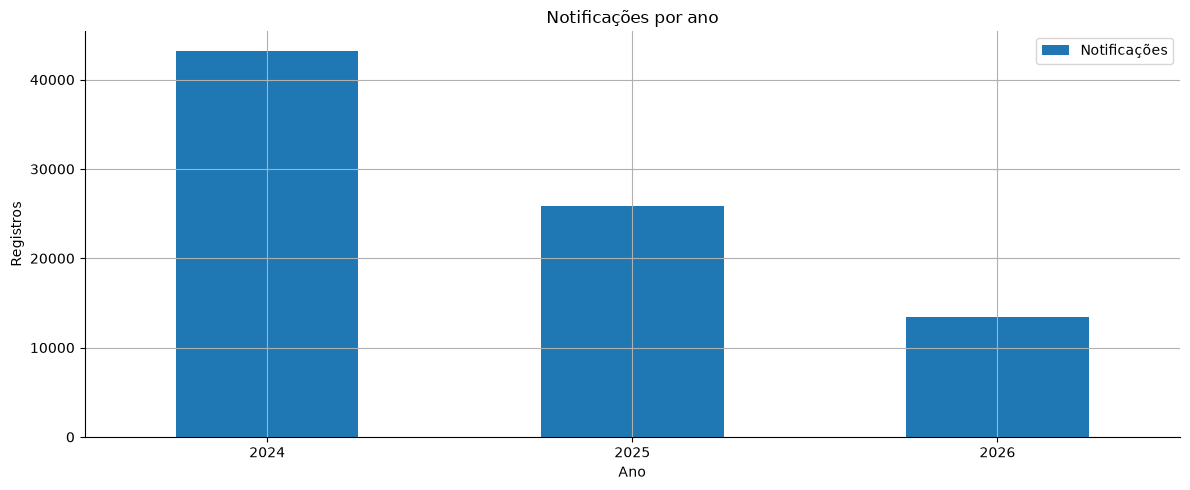

In [12]:
kpi = consultar_df("SELECT * FROM vw_kpi_anual ORDER BY ano")
display(kpi)

# Totais gerais
total = kpi[["notificacoes", "confirmados", "descartados", "inconclusivos", "obitos"]].sum()
print(f"Total de notificações: {int(total['notificacoes']):,}".replace(",", "."))
print(f"Confirmados: {int(total['confirmados']):,}".replace(",", "."))
print(f"Descartados: {int(total['descartados']):,}".replace(",", "."))
print(f"Inconclusivos: {int(total['inconclusivos']):,}".replace(",", "."))

fig, ax = plt.subplots()
kpi.set_index("ano")[["notificacoes", "confirmados", "descartados"]].plot(kind="bar", ax=ax)
ax.set_title("Notificações por ano")
ax.set_xlabel("Ano")
ax.set_ylabel("Registros")
ax.legend(["Notificações", "Confirmados", "Descartados"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 13.1 Série semanal

A semana epidemiológica é a unidade de monitoramento do SINAN. A média móvel de 4 semanas suaviza oscilações de notificação e ajuda a identificar tendência e picos.

,ano_epi,semana,inicio,fim,notificacoes,confirmados,obitos,media_dias,media_movel_4_semanas
0,2024,1,2023-12-31,2024-01-06,249,8,0,2.1,249.0
1,2024,2,2024-01-07,2024-01-13,588,21,2,3.2,418.5
2,2024,3,2024-01-14,2024-01-20,781,25,5,4.1,539.3
3,2024,4,2024-01-21,2024-01-27,895,41,2,4.1,628.3
4,2024,5,2024-01-28,2024-02-03,1068,54,3,4.8,833.0
5,2024,6,2024-02-04,2024-02-10,1265,69,8,4.2,1002.3
6,2024,7,2024-02-11,2024-02-17,1273,69,3,4.2,1125.3
7,2024,8,2024-02-18,2024-02-24,2179,105,5,4.0,1446.3
8,2024,9,2024-02-25,2024-03-02,2485,127,8,4.2,1800.5
9,2024,10,2024-03-03,2024-03-09,2731,141,12,4.1,2167.0


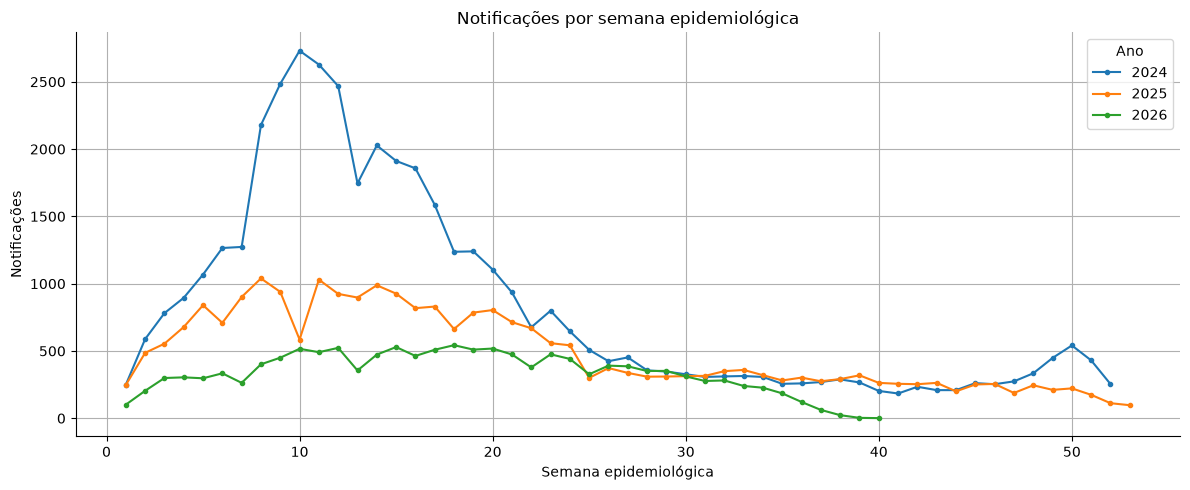

,ano_epi,semana,inicio,notificacoes,confirmados
9,2024,10,2024-03-03,2731,141
59,2025,8,2025-02-16,1039,76
122,2026,18,2026-05-03,543,16


In [13]:
serie_semanal = consultar_df("SELECT * FROM vw_serie_semanal ORDER BY ano_epi, semana")
display(serie_semanal.head(12))

fig, ax = plt.subplots()
for ano, grupo in serie_semanal.groupby("ano_epi"):
    ax.plot(grupo["semana"], grupo["notificacoes"], marker="o", markersize=3, label=str(ano))
ax.set_title("Notificações por semana epidemiológica")
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("Notificações")
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

# Pico por ano
picos = (
    serie_semanal.loc[serie_semanal.groupby("ano_epi")["notificacoes"].idxmax(),
                      ["ano_epi", "semana", "inicio", "notificacoes", "confirmados"]]
    .sort_values("ano_epi")
)
display(picos)

### 13.2 Série mensal

A visão mensal facilita comparar sazonalidade e planejar ações. Como 2024 e 2025 estão completos, eles são os melhores anos para comparação.

,ano,mes,nome_mes,notificacoes,confirmados,obitos,media_dias
0,2024,1,Janeiro,3122,125,10,3.9
1,2024,2,Fevereiro,6651,377,22,4.2
2,2024,3,Março,10382,513,36,4.1
3,2024,4,Abril,8112,358,38,5.0
4,2024,5,Maio,4526,202,33,5.9
5,2024,6,Junho,2451,144,24,9.0
6,2024,7,Julho,1731,87,11,10.3
7,2024,8,Agosto,1296,72,16,10.0
8,2024,9,Setembro,1141,43,6,14.2
9,2024,10,Outubro,931,38,8,8.2


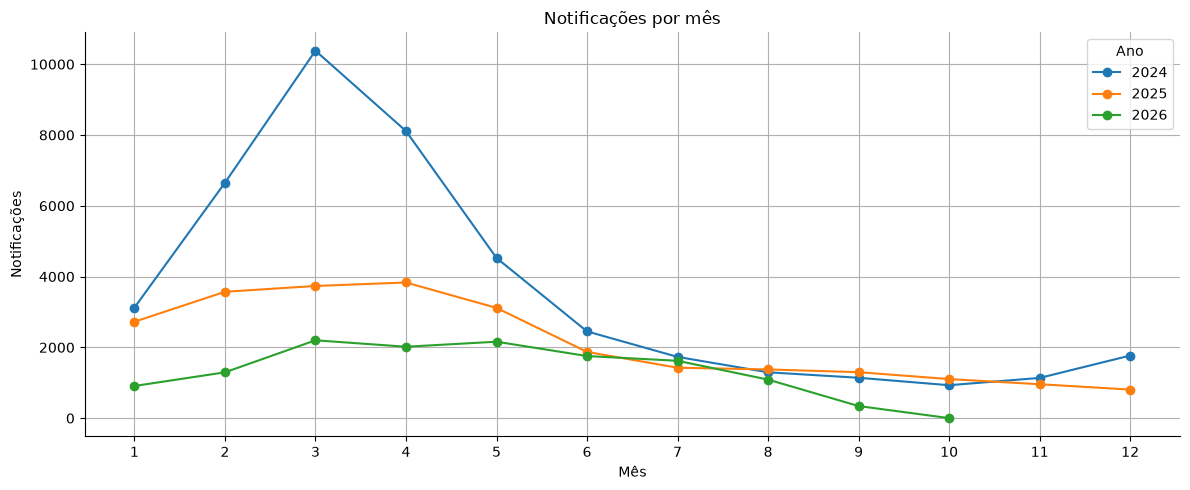

In [14]:
mensal = consultar_df("SELECT * FROM vw_serie_mensal ORDER BY ano, mes")
display(mensal)

pivot = mensal.pivot(index="mes", columns="ano", values="notificacoes")
fig, ax = plt.subplots()
for ano in pivot.columns:
    ax.plot(pivot.index, pivot[ano], marker="o", label=str(ano))
ax.set_title("Notificações por mês")
ax.set_xlabel("Mês")
ax.set_ylabel("Notificações")
ax.set_xticks(range(1, 13))
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

### 13.3 Distribuição geográfica

O ranking por UF usa a **residência** do paciente. A UF de notificação também está disponível na fato, mas pode diferir da residência. A visão `vw_por_uf` traz a participação percentual e a média de atraso.

,uf,uf_nome,regiao,notificacoes,confirmados,obitos,pct_total,media_dias
0,32,Espírito Santo,Sudeste,6860,88,33,8.32,6.3
1,50,Mato Grosso do Sul,Centro-Oeste,6726,84,33,8.16,3.5
2,26,Pernambuco,Nordeste,6680,4,36,8.10,8.3
3,51,Mato Grosso,Centro-Oeste,6476,1880,17,7.85,5.7
4,29,Bahia,Nordeste,6210,827,15,7.53,5.0
5,23,Ceará,Nordeste,6156,6,22,7.47,4.4
6,24,Rio Grande do Norte,Nordeste,5828,536,32,7.07,5.7
7,11,Rondônia,Norte,5573,157,24,6.76,6.0
8,21,Maranhão,Nordeste,4557,254,34,5.53,6.4
9,35,São Paulo,Sudeste,4483,7,56,5.44,5.3


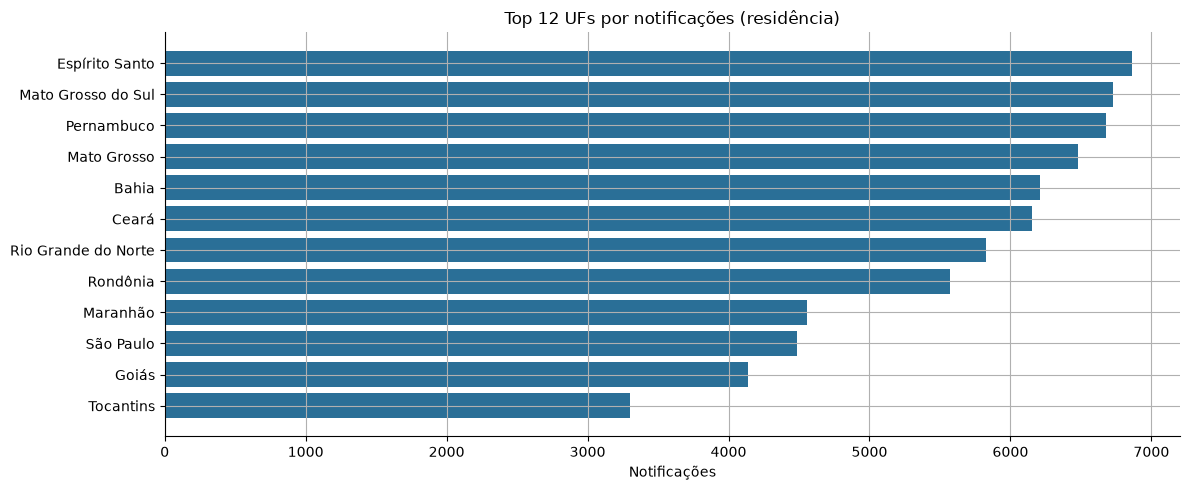

,regiao,notificacoes,confirmados,obitos,pct_total,media_dias
0,Nordeste,33824,1910,158,41.02,5.8
1,Centro-Oeste,17523,2020,81,21.25,4.5
2,Norte,15334,504,56,18.60,6.1
3,Sudeste,14648,176,106,17.76,5.9
4,Sul,1099,7,16,1.33,10.1
5,Não informado,32,2,4,0.04,5.7


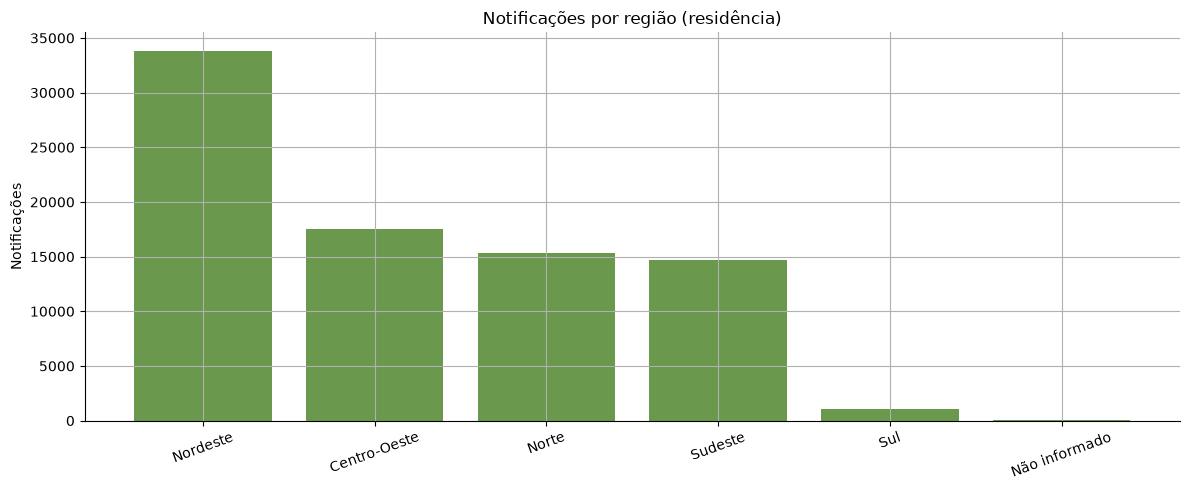

In [15]:
uf = consultar_df("SELECT * FROM vw_por_uf ORDER BY notificacoes DESC")
display(uf)

top_uf = uf.head(12).sort_values("notificacoes")
fig, ax = plt.subplots()
ax.barh(top_uf["uf_nome"], top_uf["notificacoes"], color="#2a6f97")
ax.set_title("Top 12 UFs por notificações (residência)")
ax.set_xlabel("Notificações")
plt.tight_layout()
plt.show()

regiao = consultar_df("SELECT * FROM vw_por_regiao ORDER BY notificacoes DESC")
display(regiao)

fig, ax = plt.subplots()
ax.bar(regiao["regiao"], regiao["notificacoes"], color="#6a994e")
ax.set_title("Notificações por região (residência)")
ax.set_ylabel("Notificações")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 13.4 Faixa etária e sexo

A idade é derivada de `NU_IDADE_N`, que codifica a unidade (horas, dias, meses, anos). A coluna `idade_aprox_anos` é uma aproximação para análise; o valor original é preservado em `idade_sinan`, `idade_unidade` e `idade_valor`.

,faixa_etaria,notificacoes,confirmados,obitos,pct_total
0,<1 ano,2208,124,30,2.68
1,1-4 anos,3375,217,17,4.09
2,5-9 anos,4879,266,20,5.92
3,10-14 anos,5590,327,17,6.78
4,15-19 anos,7007,382,14,8.50
5,20-29 anos,17285,796,39,20.96
6,30-39 anos,14083,735,49,17.08
7,40-49 anos,11209,640,50,13.59
8,50-59 anos,8125,500,45,9.85
9,60-69 anos,5242,357,59,6.36


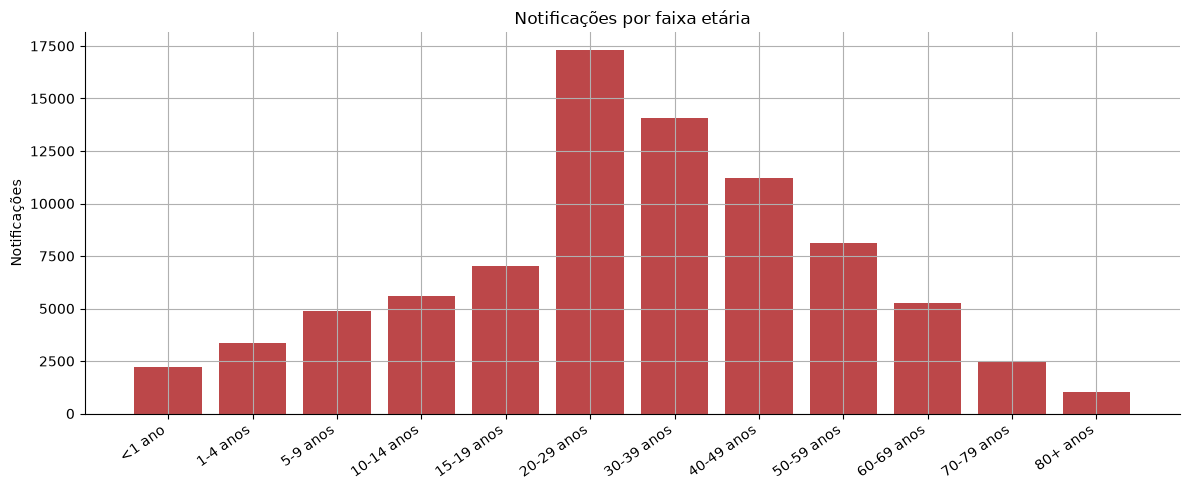

,sexo_desc,notificacoes,pct_total
0,Feminino,49591,60.14
1,Masculino,32851,39.84
2,Ignorado,18,0.02


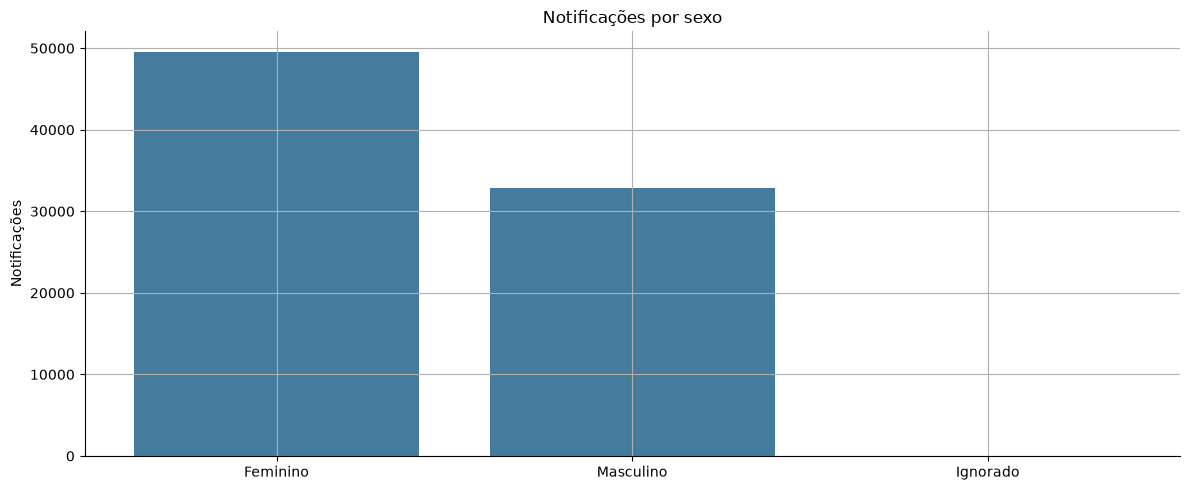

In [16]:
faixa = consultar_df("""
    SELECT * FROM vw_faixa_etaria
    ORDER BY FIELD(faixa_etaria, '<1 ano','1-4 anos','5-9 anos','10-14 anos',
                   '15-19 anos','20-29 anos','30-39 anos','40-49 anos',
                   '50-59 anos','60-69 anos','70-79 anos','80+ anos','Ignorado')
""")
display(faixa)

fig, ax = plt.subplots()
ax.bar(faixa["faixa_etaria"], faixa["notificacoes"], color="#bc4749")
ax.set_title("Notificações por faixa etária")
ax.set_ylabel("Notificações")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

sexo = consultar_df("""
    SELECT sexo_desc, COUNT(*) AS notificacoes,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_total
    FROM vw_fato_analitico
    GROUP BY sexo_desc
    ORDER BY notificacoes DESC
""")
display(sexo)

fig, ax = plt.subplots()
ax.bar(sexo["sexo_desc"], sexo["notificacoes"], color="#457b9d")
ax.set_title("Notificações por sexo")
ax.set_ylabel("Notificações")
plt.tight_layout()
plt.show()

### 13.5 Classificação, critério e evolução

A maioria das notificações de Zika é **descartada** após investigação; por isso, a taxa de confirmação é uma métrica importante. O critério indica se a confirmação foi laboratorial ou clínico-epidemiológica. A evolução mostra cura, óbito pelo agravo, óbito por outras causas ou ignorado.

,classificacao,criterio,evolucao,notificacoes
0,Descartado,Laboratorial,Cura,47264
1,Descartado,Clínico-epidemiológico,Cura,10098
2,Descartado,Laboratorial,Ignorado/Não informado,8245
3,Descartado,Clínico-epidemiológico,Ignorado/Não informado,4998
4,Inconclusivo,Ignorado/Não informado,Ignorado/Não informado,4428
5,Confirmado,Laboratorial,Cura,3219
6,Ignorado/Não informado,Ignorado/Não informado,Ignorado/Não informado,1703
7,Confirmado,Clínico-epidemiológico,Cura,699
8,Confirmado,Laboratorial,Ignorado/Não informado,450
9,Descartado,Ignorado/Não informado,Ignorado/Não informado,394


,classificacao,notificacoes
0,Descartado,71540
1,Confirmado,4619
2,Inconclusivo,4550
3,Ignorado/Não informado,1751


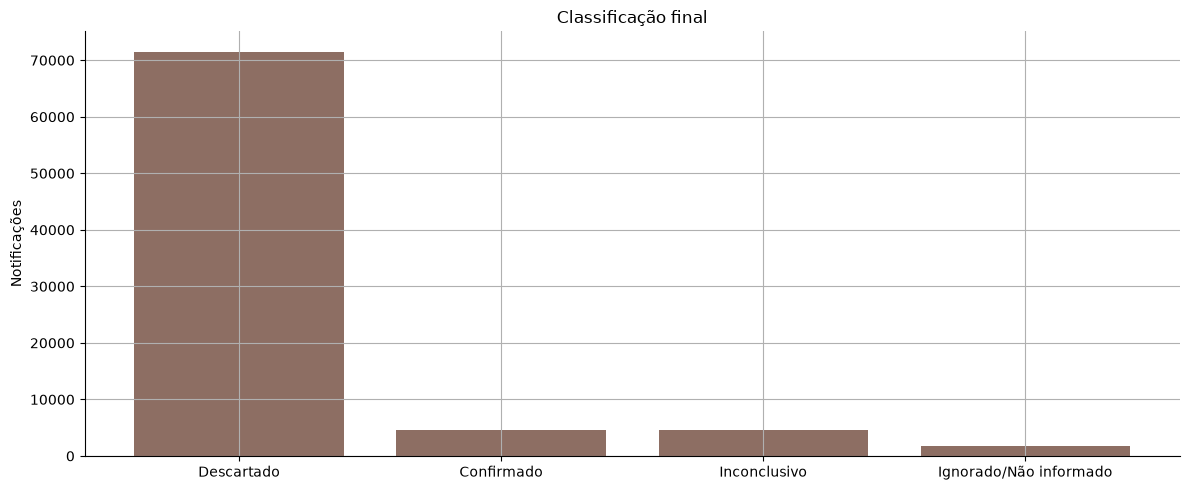

,evolucao_desc,notificacoes
0,Cura,61503
1,Ignorado/Não informado,20536
2,Óbito por outras causas,420
3,Óbito pelo agravo,1


In [17]:
classificacao = consultar_df("""
    SELECT classificacao, criterio, evolucao, SUM(notificacoes) AS notificacoes
    FROM vw_classificacao
    GROUP BY classificacao, criterio, evolucao
    ORDER BY notificacoes DESC
""")
display(classificacao.head(25))

resumo_classificacao = consultar_df("""
    SELECT classificacao, SUM(notificacoes) AS notificacoes
    FROM vw_classificacao
    GROUP BY classificacao
    ORDER BY notificacoes DESC
""")
display(resumo_classificacao)

fig, ax = plt.subplots()
ax.bar(resumo_classificacao["classificacao"], resumo_classificacao["notificacoes"], color="#8d6e63")
ax.set_title("Classificação final")
ax.set_ylabel("Notificações")
plt.tight_layout()
plt.show()

evolucao = consultar_df("""
    SELECT evolucao_desc, COUNT(*) AS notificacoes
    FROM vw_fato_analitico
    GROUP BY evolucao_desc
    ORDER BY notificacoes DESC
""")
display(evolucao)

### 13.6 Atraso entre sintomas e notificação

O atraso é `DT_NOTIFIC - DT_SIN_PRI`, em dias. Valores negativos indicam sintomas posteriores à notificação (alerta de qualidade). A mediana e os percentis são calculados no Python para complementar a visão SQL.

,com_sintomas,media,minimo,maximo,negativos,mesmo_dia,ate_7_dias,acima_30_dias,pct_ate_7_dias
0,82460,5.7,0,356,0,7383,61292,1827,83.3


,dias_sintomas_notificacao,notificacoes
0,0,7383
1,1,12485
2,2,11715
3,3,12050
4,4,8946
5,5,6754
6,6,4866
7,7,4476
8,8,2638
9,9,1714


Mediana: 3 dias
P25: 2 dias | P75: 6 dias | P90: 10 dias


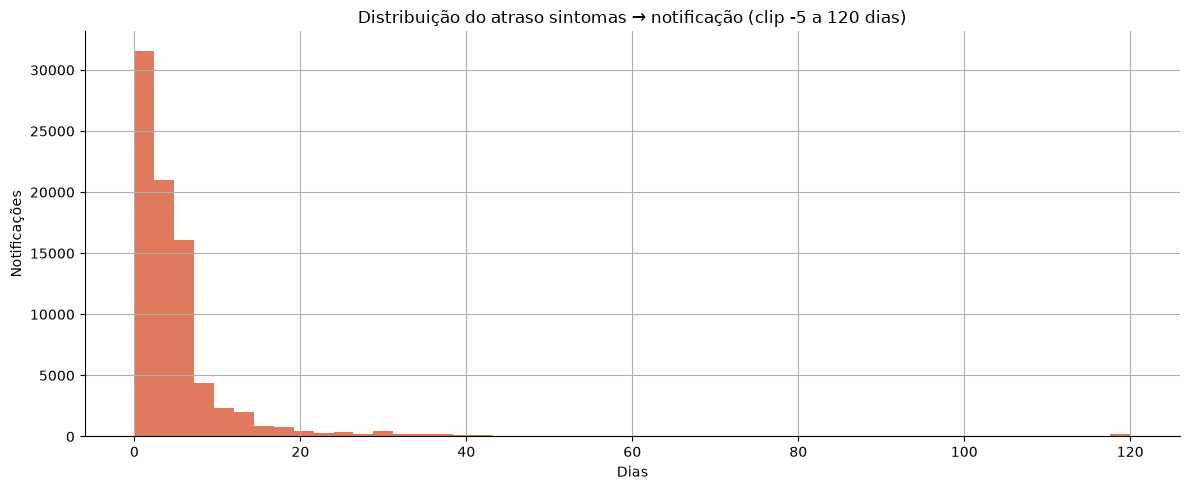

In [18]:
atraso_resumo = consultar_df("SELECT * FROM vw_atraso_resumo")
display(atraso_resumo)

atraso = consultar_df("SELECT * FROM vw_atraso_notificacao ORDER BY dias_sintomas_notificacao")
display(atraso.head(20))

dias = consultar_df("""
    SELECT dias_sintomas_notificacao
    FROM fato_notificacao
    WHERE dias_sintomas_notificacao IS NOT NULL
""")["dias_sintomas_notificacao"]
print(f"Mediana: {dias.median():.0f} dias")
print(f"P25: {dias.quantile(0.25):.0f} dias | P75: {dias.quantile(0.75):.0f} dias | P90: {dias.quantile(0.90):.0f} dias")

fig, ax = plt.subplots()
ax.hist(dias.clip(lower=-5, upper=120), bins=50, color="#e07a5f")
ax.set_title("Distribuição do atraso sintomas → notificação (clip -5 a 120 dias)")
ax.set_xlabel("Dias")
ax.set_ylabel("Notificações")
plt.tight_layout()
plt.show()

### 13.7 Gestantes

O recorte de gestantes considera mulheres com `CS_GESTANT` igual a 1, 2, 3 ou 4 (trimestres ou idade gestacional ignorada). Códigos 5 (não) e 6 (não se aplica) são excluídos. A Zika em gestantes é um evento de especial interesse porque há associação com microcefalia e outras complicações.

In [19]:
gestantes = consultar_df("SELECT * FROM vw_gestantes ORDER BY notificacoes DESC")
display(gestantes)

# Distribuição por trimestre
trimestres = consultar_df("""
    SELECT gestante_desc, COUNT(*) AS notificacoes,
           SUM(classificacao_final = '1') AS confirmados
    FROM vw_fato_analitico
    WHERE sexo = 'F' AND gestante IN ('1','2','3','4')
    GROUP BY gestante_desc
    ORDER BY notificacoes DESC
""")
display(trimestres)

,gestante_desc,faixa_etaria,notificacoes,confirmados,obitos
0,3º trimestre,20-29 anos,1387,35,3
1,2º trimestre,20-29 anos,1382,43,1
2,1º trimestre,20-29 anos,996,26,1
3,3º trimestre,30-39 anos,803,18,0
4,2º trimestre,30-39 anos,771,19,0
5,1º trimestre,30-39 anos,546,11,0
6,2º trimestre,15-19 anos,331,15,0
7,3º trimestre,15-19 anos,291,13,1
8,1º trimestre,15-19 anos,216,15,0
9,2º trimestre,40-49 anos,76,1,0


,gestante_desc,notificacoes,confirmados
0,2º trimestre,2588,79
1,3º trimestre,2571,67
2,1º trimestre,1840,55
3,Idade gestacional ignorada,184,6


### 13.8 Qualidade em profundidade

Esta seção investiga os principais alertas:

- quantas notificações têm `SEM_NOT` incoerente com `DT_NOTIFIC`;
- quais UFs concentram residência incompleta;
- exemplos de duplicidade exata;
- evolução dos alertas por arquivo.

In [20]:
# SEM_NOT incoerente por ano
incoerencia = consultar_df("""
    SELECT f.ano_notificacao AS ano,
           COUNT(*) AS notificacoes,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY f.ano_notificacao), 2) AS pct
    FROM fato_notificacao f
    JOIN dim_semana_epidemiologica s ON s.codigo = f.semana_notificacao
    WHERE f.data_notificacao < s.inicio OR f.data_notificacao > s.fim
    GROUP BY f.ano_notificacao
    ORDER BY ano
""")
display(incoerencia)

# Residência incompleta por UF
geo_incompleta = consultar_df("""
    SELECT g.uf, g.uf_nome, COUNT(*) AS notificacoes
    FROM fato_notificacao f
    JOIN dim_geografia g ON g.chave = f.geografia_residencia
    WHERE g.uf IS NULL OR g.municipio IS NULL
    GROUP BY g.uf, g.uf_nome
    ORDER BY notificacoes DESC
""")
display(geo_incompleta.head(15))

# Duplicidades
duplicados = consultar_df("SELECT * FROM vw_duplicados ORDER BY ocorrencias DESC")
display(duplicados.head(20))

# Resumo de alertas por arquivo
alertas_arquivo = consultar_df("""
    SELECT arquivo_fonte, regra, severidade, ocorrencias
    FROM etl_qualidade
    WHERE execucao_id = %s AND severidade = 'ALERTA' AND ocorrencias > 0
    ORDER BY arquivo_fonte, ocorrencias DESC
""", (EXECUCAO_ID,))
display(alertas_arquivo)

# Completude geográfica
completude = consultar_df("SELECT * FROM vw_qualidade_geo ORDER BY notificacoes DESC")
display(completude)

,ano,notificacoes,pct
0,2024,5358,100.00
1,2025,69,100.00


,uf,uf_nome,notificacoes
0,None,None,32


,arquivo_fonte,hash_linha,ocorrencias
0,ZIKABR25.csv,35990ba769ecc4893dc48864730720eb78f7d936e0ad9a145af76346e4d21dde,2
1,ZIKABR24.csv,af0661efc213ba1622ac18113bd4d305f4037964090ac935043677847caf936b,2
2,ZIKABR24.csv,b773df04959f59c8deabb6a7f8e00e4a300b2522bbdd343585157bc3bcef412a,2
3,ZIKABR24.csv,c042940f705173602190b730e00d48a0b70499be730f9c9423aba8af95a35d61,2
4,ZIKABR24.csv,ca62da6a9b356691955280c40c2ca4afa91e3a54f9b5082839ae3aa31866738e,2
5,ZIKABR24.csv,d01699ae05556bd2b274553e87864c6c48885ced45d073e54bb37995dd999600,2
6,ZIKABR24.csv,da2a03a81c31ddabdd1725bce1e84e580a143445c2375b61b984774c68a68e73,2
7,ZIKABR24.csv,db497586a45fcb12278d2ba81af23903038bde01e6dc09bd0171fbe9160a8ede,2
8,ZIKABR24.csv,e135e0ffde42cd10c943f760edbe200340f00a85b30b226afbd7114b0481e4bb,2
9,ZIKABR24.csv,e7e6007f9b620341addb2c1ee32555a271a2074941904139f0e0bfa09392666b,2


,arquivo_fonte,regra,severidade,ocorrencias
0,TODOS,evolução ausente,ALERTA,11987
1,TODOS,critério ausente,ALERTA,6673
2,TODOS,SEM_PRI incoerente com DT_SIN_PRI,ALERTA,5427
3,TODOS,SEM_NOT incoerente com DT_NOTIFIC,ALERTA,5427
4,TODOS,atraso de notificação acima de 30 dias,ALERTA,1827
5,TODOS,classificação final ausente,ALERTA,1724
6,TODOS,duplicidade exata,ALERTA,112
7,TODOS,residência incompleta,ALERTA,32
8,TODOS,digitação anterior à notificação,ALERTA,21
9,TODOS,encerramento anterior à notificação,ALERTA,13


,nivel,notificacoes,pct_total
0,completo,82428,99.96
1,sem_uf,32,0.04


## 14. Auditoria, exportação e manifesto

A auditoria mostra o que aconteceu em cada etapa: linhas lidas, staging, rejeitadas, fato, duração e status. O manifesto registra a execução, o hash dos arquivos e as versões do ambiente, permitindo reproduzir ou investigar uma carga posteriormente.

As visões analíticas são exportadas para `saidas/` em CSV, prontas para abrir no Excel, Power BI ou outra ferramenta.

In [ ]:
auditoria = consultar_df("""
    SELECT arquivo_fonte, etapa, status, linhas_lidas, linhas_staging,
           linhas_rejeitadas, linhas_fato, duracao_seg, iniciado_em, finalizado_em
    FROM etl_execucao
    WHERE execucao_id = %s
    ORDER BY arquivo_fonte, FIELD(etapa, 'staging', 'qualidade', 'fato')
""", (EXECUCAO_ID,))
display(auditoria)

qualidade_final = consultar_df("""
    SELECT arquivo_fonte, regra, severidade, ocorrencias
    FROM etl_qualidade
    WHERE execucao_id = %s
    ORDER BY severidade, arquivo_fonte, ocorrencias DESC
""", (EXECUCAO_ID,))
display(qualidade_final)

# Exportações
SAIDAS.mkdir(parents=True, exist_ok=True)
exportacoes = {
    "kpi_anual": kpi,
    "serie_semanal": serie_semanal,
    "serie_mensal": mensal,
    "por_uf": uf,
    "por_regiao": regiao,
    "faixa_etaria": faixa,
    "gestantes": gestantes,
    "classificacao": classificacao,
    "atraso_resumo": atraso_resumo,
    "qualidade_geo": completude,
    "auditoria": auditoria,
    "qualidade": qualidade_final,
}
for nome, df in exportacoes.items():
    caminho = SAIDAS / f"{nome}.csv"
    df.to_csv(caminho, index=False, encoding="utf-8-sig")
    print(f"Exportado: {caminho}")

# Manifesto da execução
manifesto = {
    "execucao_id": EXECUCAO_ID,
    "inicio": INICIO_EXECUCAO.isoformat(timespec="seconds"),
    "fim": datetime.now().isoformat(timespec="seconds"),
    "banco": BANCO,
    "diretorio_dados": str(DIRETORIO_DADOS),
    "chunksize": CHUNKSIZE,
    "arquivos": {
        nome: {
            "ano_referencia": meta["ano_referencia"],
            "periodo": meta["periodo"],
            "linhas": staging[nome]["linhas"],
            "sha256": staging[nome]["hash"],
        }
        for nome, meta in ARQUIVOS.items()
    },
    "contagens": {
        "csv": TOTAL_LINHAS_CSV,
        "staging": sum(v["linhas"] for v in staging.values()),
        "fato": sum(v["fato"] for v in fato.values()),
        "rejeitadas": sum(v["rejeitadas"] for v in qualidade_staging.values()),
    },
    "qualidade": {
        "verificacoes": len(scorecard),
        "alertas": int((scorecard["status"] == "ALERTA").sum()),
        "falhas": int((scorecard["status"] == "FALHA").sum()),
    },
    "versoes": {
        "python": __import__("sys").version.split()[0],
        "mysql": versao,
        "pandas": pd.__version__,
        "matplotlib": __import__("matplotlib").__version__,
    },
}
caminho_manifesto = SAIDAS / "manifesto_execucao.json"
caminho_manifesto.write_text(
    json.dumps(manifesto, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"\nManifesto: {caminho_manifesto}")
display(pd.DataFrame([manifesto["contagens"]]))

,arquivo_fonte,etapa,status,linhas_lidas,linhas_staging,linhas_rejeitadas,linhas_fato,duracao_seg,iniciado_em,finalizado_em
0,ZIKABR24.csv,staging,SUCESSO,43312,43312.0,NaN,NaN,6.642,2026-11-09 14:49:26,2026-11-09 14:49:34
1,ZIKABR24.csv,qualidade,SUCESSO,43312,43312.0,0.0,NaN,4.046,2026-11-09 14:49:43,2026-11-09 14:49:44
2,ZIKABR24.csv,fato,SUCESSO,43312,NaN,0.0,43312.0,10.984,2026-11-09 14:50:04,2026-11-09 14:50:16
3,ZIKABR25.csv,staging,SUCESSO,25764,25764.0,NaN,NaN,3.818,2026-11-09 14:49:33,2026-11-09 14:49:38
4,ZIKABR25.csv,qualidade,SUCESSO,25764,25764.0,0.0,NaN,2.319,2026-11-09 14:49:46,2026-11-09 14:49:46
5,ZIKABR25.csv,fato,SUCESSO,25764,NaN,0.0,25764.0,9.789,2026-11-09 14:50:16,2026-11-09 14:50:26
6,ZIKABR26.csv,staging,SUCESSO,13384,13384.0,NaN,NaN,2.173,2026-11-09 14:49:37,2026-11-09 14:49:40
7,ZIKABR26.csv,qualidade,SUCESSO,13384,13384.0,0.0,NaN,1.232,2026-11-09 14:49:47,2026-11-09 14:49:47
8,ZIKABR26.csv,fato,SUCESSO,13384,NaN,0.0,13384.0,4.336,2026-11-09 14:50:26,2026-11-09 14:50:31


,arquivo_fonte,regra,severidade,ocorrencias
0,TODOS,staging == CSV [ZIKABR24.csv],CRITICA,43312
1,TODOS,fato == staging válido [ZIKABR24.csv],CRITICA,43312
2,TODOS,staging == CSV [ZIKABR25.csv],CRITICA,25764
3,TODOS,fato == staging válido [ZIKABR25.csv],CRITICA,25764
4,TODOS,staging == CSV [ZIKABR26.csv],CRITICA,13384
...,...,...,...,...
111,ZIKABR26.csv,DIGITACAO_ANTES_NOTIFICACAO,ALERTA,0
112,ZIKABR26.csv,OBITO_ANTES_SINTOMAS,ALERTA,0
113,ZIKABR26.csv,OBITO_SEM_EVOLUCAO_COMPATIVEL,ALERTA,0
114,ZIKABR26.csv,UF_INVALIDA,ALERTA,0


Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/kpi_anual.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/serie_semanal.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/serie_mensal.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/por_uf.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/por_regiao.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/faixa_etaria.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/gestantes.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/classificacao.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/atraso_resumo.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/qualidade_geo.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/auditoria.csv
Exportado: /home/arthur/Documentos/banco_de_dados/zika_Virus/saidas/qualidade.

,csv,staging,fato,rejeitadas
0,82460,82460,82460,0


### Comandos úteis

```sql
-- Contagem por arquivo
SELECT arquivo_fonte, COUNT(*) FROM fato_notificacao GROUP BY arquivo_fonte;

-- Últimas execuções
SELECT * FROM etl_execucao ORDER BY iniciado_em DESC LIMIT 20;

-- Alertas da execução
SELECT * FROM etl_qualidade WHERE severidade = 'ALERTA' AND ocorrencias > 0;

-- Amostra da fato desnormalizada
SELECT * FROM vw_fato_analitico LIMIT 10;
```

```python
# Reexecutar uma análise específica
consultar_df("SELECT * FROM vw_kpi_anual ORDER BY ano")
```